# Nipun Semantic Evaluation & Model Verification Benchmark
**Platform**: Nipun AI Resume Screener & Ranking System (`saaket2006/nipun-platform`)  
**Scope**: Controlled Evaluation of Skill Knowledge Base, Normalizer, Semantic Resolver, Matcher, and Scorer  

---

### Executive Summary & Methodological Governance
This notebook provides a quantitative, reproducible evaluation of the semantic matching and scoring intelligence layer used in the Nipun platform.

> #### Strict Governance Principles
> 1. **No Resumes or PII**: This evaluation operates exclusively on the structured knowledge base (`knowledge_base/skills.json`) and controlled test vectors. No candidate resumes, parsed documents, or personal data are loaded or processed.
> 2. **No Fabricated Predictive Metrics**: Standard external predictive metrics (**Accuracy**, **Precision**, **Recall**, **F1-Score**, **ROC-AUC**) are **strictly omitted** because the repository does not contain an independent, recruiter-labeled hiring benchmark. Reporting such metrics against internal taxonomy rules would be circular validation.
> 3. **Distinction of Key Quantities**:
>    - **Configured Policy Weights ($w_i$)**: Deterministic business rules ($1.00, 0.95, 0.90, 0.75, 0.60, 0.00$) configured in `config.py` for ranking candidate fit, not statistical probabilities.
>    - **Resolver Confidence**: Confidence returned by the semantic resolver reflecting relationship certainty under taxonomy rules.
>    - **Normalizer String Confidence**: Lexical edit-distance confidence ($1.00$ exact, $0.90$ alias, $0.80$ abbreviation) assigned during raw token pre-processing.
> 4. **Internal Implementation Consistency**: The 100% rule-consistency metric measures software fidelity to its own taxonomy and precedence cascades, not external hiring accuracy.
> 5. **Counting Methodology (Total N = 317)**: Evaluates 317 structured test cases consisting of 289 canonical pairwise combinations ($17 \times 17$ matrix: 17 diagonal self-comparisons + 272 off-diagonal comparisons) plus 28 lexical-variant evaluations (21 aliases + 7 abbreviations). These represent taxonomy verification cases, not independent real-world resume samples.
> 6. **Separation of Baseline vs. Edge Cases**: Core baseline evaluations ($317$ cases, $17 \times 17$ canonical matrix, $3$ controlled scenarios) remain isolated from supplementary edge-case robustness tests (Experiment E).


In [1]:
# Cell 1: Environment Setup, Module Imports, & Knowledge Base Loading
import sys
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure repository root is on sys.path
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Set reproducible plotting defaults
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.sans-serif': ['DejaVu Sans', 'Arial', 'Helvetica'],
    'axes.edgecolor': '#cccccc',
    'axes.linewidth': 0.8,
    'figure.autolayout': False,
    'figure.dpi': 150
})

# Configure output directory
OUTPUT_DIR = repo_root / 'notebooks' / 'evaluation_results'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Load Knowledge Base via Production Singleton Loader
from backend.services.skills.loader import get_skills_loader
from backend.services.skills.models import Skill
from backend.services.semantic.config import SEMANTIC_WEIGHTS, get_weight

canonical_skills = get_skills_loader()
n_skills = len(canonical_skills)
print(f'Successfully loaded {n_skills} canonical skills from knowledge base.')
assert n_skills == 17, f'Expected 17 canonical skills, found {n_skills}'


Successfully loaded 17 canonical skills from knowledge base.


## 1. Configured Semantic Scoring Policy Weights

### Overview
The semantic matching layer assigns deterministic policy weights according to the degree of relationship identified between a required skill and a candidate skill. These weights are configured in `backend/services/semantic/config.py`.

| Relationship Type | Policy Weight | Confidence | Semantic Meaning |
| :--- | :---: | :---: | :--- |
| **EXACT** | **1.00** | 1.00 | Exact canonical ID equality or case-insensitive string match. |
| **ALIAS** | **0.95** | 0.95 | Synonymous naming variant declared in taxonomy (e.g., `Postgres` $\to$ `PostgreSQL`). |
| **ABBREVIATION** | **0.90** | 0.90 | Recognized acronym/abbreviation (e.g., `K8s` $\to$ `Kubernetes`, `LLM` $\to$ `Large Language Models`). |
| **HIERARCHICAL** | **0.75** | 0.75 | Sibling framework/library sharing identical `category` and `subcategory` (e.g., `FastAPI` $\leftrightarrow$ `Flask`). |
| **TECHNOLOGY_FAMILY** | **0.60** | 0.60 | Cross-category shared engineering domain (e.g., `Python` $\leftrightarrow$ `FastAPI`, `JavaScript` $\leftrightarrow$ `React`). |
| **UNKNOWN** | **0.00** | 0.00 | Orthogonal skills with no recognized taxonomic relationship. |

> **Note on String Confidence vs. Policy Weights**: When `SkillNormalizer` pre-processes raw strings, it assigns a string confidence (1.0 for verbatim, 0.9 for alias, 0.8 for acronym). In contrast, the weights above are semantic relationship weights applied during skill-to-skill matching.


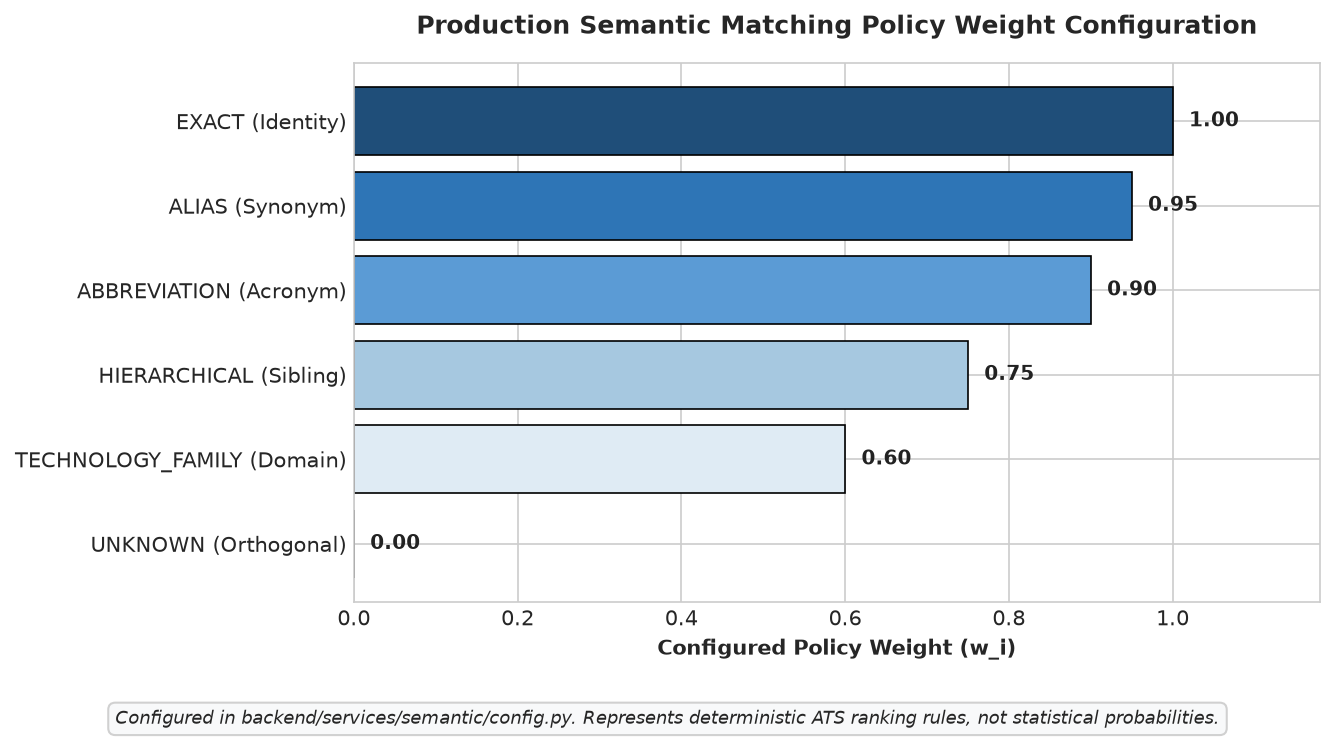

Saved: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\configured_weights_comparison.png


In [2]:
# Cell 2: Visualization of Configured Policy Weights
weight_names = [
    'EXACT (Identity)',
    'ALIAS (Synonym)',
    'ABBREVIATION (Acronym)',
    'HIERARCHICAL (Sibling)',
    'TECHNOLOGY_FAMILY (Domain)',
    'UNKNOWN (Orthogonal)'
]
raw_tiers = ['EXACT', 'ALIAS', 'ABBREVIATION', 'HIERARCHICAL', 'TECHNOLOGY_FAMILY', 'UNKNOWN']
weight_values = [get_weight(w) for w in raw_tiers]
colors = ['#1f4e79', '#2e75b6', '#5b9bd5', '#a6c8e0', '#dfebf4', '#d9534f']

fig1, ax1 = plt.subplots(figsize=(9, 4.6))
bars1 = ax1.barh(weight_names[::-1], weight_values[::-1], color=colors[::-1], edgecolor='black', linewidth=0.8)

for bar in bars1:
    w = bar.get_width()
    ax1.text(w + 0.02, bar.get_y() + bar.get_height() / 2, f'{w:.2f}',
             va='center', ha='left', fontsize=9.5, fontweight='bold', color='#222222')

ax1.set_xlim(0, 1.18)
ax1.set_xlabel('Configured Policy Weight (w_i)', fontsize=10, fontweight='bold')
ax1.set_title('Production Semantic Matching Policy Weight Configuration', fontsize=12, fontweight='bold', pad=14)

caption1 = 'Configured in backend/services/semantic/config.py. Represents deterministic ATS ranking rules, not statistical probabilities.'
plt.figtext(0.5, -0.04, caption1, ha='center', va='top', fontsize=8.5, style='italic',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#f8f9fa', edgecolor='#cccccc', alpha=0.9))

plt.tight_layout()
p1_path = OUTPUT_DIR / 'configured_weights_comparison.png'
fig1.savefig(p1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {p1_path}')


## 2. Experiment A: Semantic Match Score Analysis

### Objective
Evaluate the distribution of relationship types, returned match confidences, and match weights produced by the project's semantic resolver (`resolve_relationship`).

### Relationship Types & Cascade Order
The current implementation in `backend/services/semantic/resolver.py` executes an ordered rule cascade:
1. **EXACT Match**: Canonical ID equality or case-insensitive name match (`weight: 1.00`, `confidence: 1.0`).
2. **ALIAS Match**: Candidate name matches a declared alias of required skill, or vice-versa (`weight: 0.95`, `confidence: 0.95`).
3. **ABBREVIATION Match**: Candidate name matches a declared abbreviation, or vice-versa (`weight: 0.90`, `confidence: 0.90`).
4. **HIERARCHICAL Match**: Sibling skills sharing identical `category` and `subcategory` (excluding Unknown) (`weight: 0.75`, `confidence: 0.75`).
5. **TECHNOLOGY_FAMILY Match**: Cross-category skills sharing identical `technology_family`, or direct family association (`weight: 0.60`, `confidence: 0.60`).
6. **UNKNOWN Match**: Fallback when no taxonomic relationship is satisfied (`weight: 0.00`, `confidence: 0.0`).

### Evaluated Comparisons Space (Total N = 317)
- **289 Canonical Pairwise Comparisons** ($17 \times 17$ matrix): 17 diagonal identity self-comparisons + 272 off-diagonal comparisons.
- **21 Alias Comparisons**: Every declared alias tested against its parent canonical skill.
- **7 Abbreviation Comparisons**: Every declared abbreviation tested against its parent canonical skill.
- **Total Evaluated Comparisons**: $289 + 21 + 7 = 317$ comparisons.

> **Methodological Clarification**: The 317 cases represent structured evaluation points combining canonical pairwise relationships and declared lexical variants. They must not be interpreted as 317 independent candidate profiles or real-world applicant distributions.


In [3]:
# Cell 3: Experiment A Execution — Comprehensive Relationship Analysis
from backend.services.semantic.resolver import resolve_relationship

# 1. Evaluate Canonical Pairwise Space (17 x 17 = 289 evaluations)
pairwise_evaluations = []
for i, req in enumerate(canonical_skills):
    for j, cand in enumerate(canonical_skills):
        m_type, conf, weight, reason = resolve_relationship(req, cand)
        pairwise_evaluations.append({
            'req_name': req.canonical_name,
            'cand_name': cand.canonical_name,
            'is_diagonal': (i == j),
            'match_type': m_type,
            'confidence': conf,
            'weight': weight,
            'reason': reason,
            'comparison_source': 'canonical_pairwise'
        })
df_pairwise = pd.DataFrame(pairwise_evaluations)

# 2. Evaluate Defined Alias Relationships (21 alias test cases)
alias_evaluations = []
for s in canonical_skills:
    for alias in s.aliases:
        alias_skill = Skill(
            id=f'alias.{alias.lower().replace(" ", "_")}',
            canonical_name=alias,
            category='Unknown',
            subcategory='Unknown',
            technology_family='Unknown'
        )
        m_type, conf, weight, reason = resolve_relationship(s, alias_skill)
        alias_evaluations.append({
            'req_name': s.canonical_name,
            'cand_name': alias,
            'is_diagonal': False,
            'match_type': m_type,
            'confidence': conf,
            'weight': weight,
            'reason': reason,
            'comparison_source': 'alias_test'
        })
df_alias_eval = pd.DataFrame(alias_evaluations)

# 3. Evaluate Defined Abbreviation Relationships (7 abbreviation test cases)
abbr_evaluations = []
for s in canonical_skills:
    for abbr in s.abbreviations:
        abbr_skill = Skill(
            id=f'abbr.{abbr.lower().replace(" ", "_")}',
            canonical_name=abbr,
            category='Unknown',
            subcategory='Unknown',
            technology_family='Unknown'
        )
        m_type, conf, weight, reason = resolve_relationship(s, abbr_skill)
        abbr_evaluations.append({
            'req_name': s.canonical_name,
            'cand_name': abbr,
            'is_diagonal': False,
            'match_type': m_type,
            'confidence': conf,
            'weight': weight,
            'reason': reason,
            'comparison_source': 'abbreviation_test'
        })
df_abbr_eval = pd.DataFrame(abbr_evaluations)

# Combine all structured evaluation cases (Total = 317)
df_all_eval = pd.concat([df_pairwise, df_alias_eval, df_abbr_eval], ignore_index=True)
total_evaluations_count = len(df_all_eval)
print(f'Total Evaluated Comparisons: {total_evaluations_count}')
print(f'  - Canonical Pairwise Comparisons: {len(df_pairwise)} (Diagonal: {df_pairwise["is_diagonal"].sum()}, Off-Diagonal: {(~df_pairwise["is_diagonal"]).sum()})')
print(f'  - Explicit Alias Comparisons: {len(df_alias_eval)}')
print(f'  - Explicit Abbreviation Comparisons: {len(df_abbr_eval)}')

# Summarize Results by Match Type
summary_data = []
for m_type in raw_tiers:
    sub = df_all_eval[df_all_eval['match_type'] == m_type]
    cnt = len(sub)
    pct = (cnt / total_evaluations_count) * 100
    cfg_w = get_weight(m_type)
    mean_w = sub['weight'].mean() if cnt > 0 else 0.0
    med_w = sub['weight'].median() if cnt > 0 else 0.0
    min_w = sub['weight'].min() if cnt > 0 else 0.0
    max_w = sub['weight'].max() if cnt > 0 else 0.0
    mean_c = sub['confidence'].mean() if cnt > 0 else 0.0
    summary_data.append({
        'Relationship Type': m_type,
        'Evaluated Matches': cnt,
        'Share of Total (%)': round(pct, 2),
        'Successful Matches': cnt if m_type != 'UNKNOWN' else 0,
        'Unmatched Count': cnt if m_type == 'UNKNOWN' else 0,
        'Configured Policy Weight': cfg_w,
        'Mean Weight': round(mean_w, 2),
        'Median Weight': round(med_w, 2),
        'Min Weight': round(min_w, 2),
        'Max Weight': round(max_w, 2),
        'Mean Confidence': round(mean_c, 2)
    })

df_exp_a_summary = pd.DataFrame(summary_data)
print('\n=== EXPERIMENT A: RELATIONSHIP EVALUATION SUMMARY (Total N = 317) ===')
display(df_exp_a_summary[['Relationship Type', 'Evaluated Matches', 'Share of Total (%)', 'Configured Policy Weight', 'Mean Weight', 'Mean Confidence']])


Total Evaluated Comparisons: 317
  - Canonical Pairwise Comparisons: 289 (Diagonal: 17, Off-Diagonal: 272)
  - Explicit Alias Comparisons: 21
  - Explicit Abbreviation Comparisons: 7

=== EXPERIMENT A: RELATIONSHIP EVALUATION SUMMARY (Total N = 317) ===


,Relationship Type,Evaluated Matches,Share of Total (%),Configured Policy Weight,Mean Weight,Mean Confidence
0,EXACT,20,6.31,1.00,1.00,1.00
1,ALIAS,23,7.26,0.95,0.95,0.95
2,ABBREVIATION,2,0.63,0.90,0.90,0.90
3,HIERARCHICAL,6,1.89,0.75,0.75,0.75
4,TECHNOLOGY_FAMILY,42,13.25,0.60,0.60,0.60
5,UNKNOWN,224,70.66,0.00,0.00,0.00


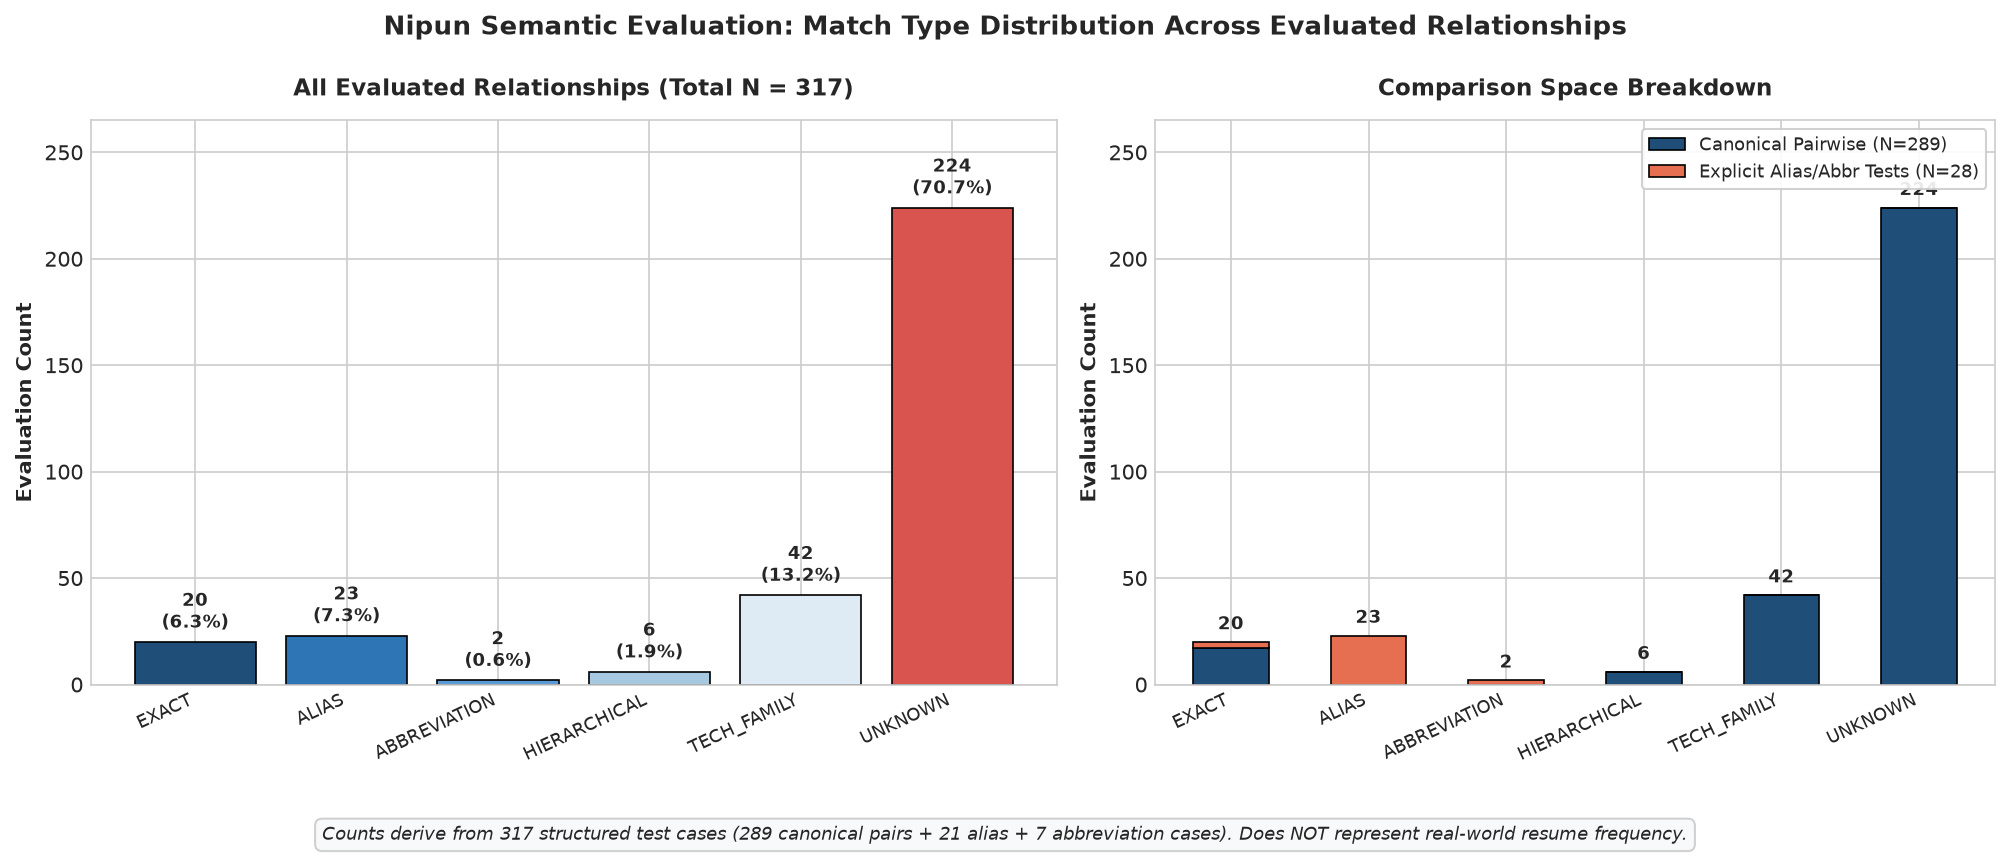

Saved: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\match_type_distribution.png


In [4]:
# Cell 4: Experiment A Visualization 1 — Match Type Distribution (Dual Panel)
fig2, (ax2a, ax2b) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={'width_ratios': [1.15, 1]})

# Subplot 1: All Evaluated Relationships (N = 317)
bar_colors = ['#1f4e79', '#2e75b6', '#5b9bd5', '#a6c8e0', '#dfebf4', '#d9534f']
display_tiers = ['EXACT', 'ALIAS', 'ABBREVIATION', 'HIERARCHICAL', 'TECH_FAMILY', 'UNKNOWN']
bars_a = ax2a.bar(range(len(display_tiers)), df_exp_a_summary['Evaluated Matches'],
                  color=bar_colors, edgecolor='black', linewidth=0.8)
for bar, pct in zip(bars_a, df_exp_a_summary['Share of Total (%)']):
    h = bar.get_height()
    ax2a.annotate(f'{int(h)}\n({pct:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h),
                  xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax2a.set_title('All Evaluated Relationships (Total N = 317)', fontsize=11, fontweight='bold', pad=12)
ax2a.set_ylabel('Evaluation Count', fontsize=10, fontweight='bold')
ax2a.set_xticks(range(len(display_tiers)))
ax2a.set_xticklabels(display_tiers, rotation=25, ha='right', fontsize=8.5)
ax2a.set_ylim(0, 265)

# Subplot 2: Breakdown by Comparison Space
canonical_counts = [len(df_pairwise[df_pairwise['match_type'] == m]) for m in raw_tiers]
aux_counts = [len(df_all_eval[(df_all_eval['match_type'] == m) & (df_all_eval['comparison_source'] != 'canonical_pairwise')]) for m in raw_tiers]

x_indices = np.arange(len(display_tiers))
width = 0.55
p_can = ax2b.bar(x_indices, canonical_counts, width, label='Canonical Pairwise (N=289)', color='#1f4e79', edgecolor='black', linewidth=0.8)
p_aux = ax2b.bar(x_indices, aux_counts, width, bottom=canonical_counts, label='Explicit Alias/Abbr Tests (N=28)', color='#e76f51', edgecolor='black', linewidth=0.8)

for i, (c_cnt, a_cnt) in enumerate(zip(canonical_counts, aux_counts)):
    tot = c_cnt + a_cnt
    if tot > 0:
        ax2b.text(i, tot + 4, str(tot), ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax2b.set_title('Comparison Space Breakdown', fontsize=11, fontweight='bold', pad=12)
ax2b.set_xticks(x_indices)
ax2b.set_xticklabels(display_tiers, rotation=25, ha='right', fontsize=8.5)
ax2b.set_ylabel('Evaluation Count', fontsize=10, fontweight='bold')
ax2b.set_ylim(0, 265)
ax2b.legend(frameon=True, loc='upper right', framealpha=0.9, fontsize=8.5)

plt.suptitle('Nipun Semantic Evaluation: Match Type Distribution Across Evaluated Relationships',
             fontsize=12.5, fontweight='bold', y=0.99)

caption2 = 'Counts derive from 317 structured test cases (289 canonical pairs + 21 alias + 7 abbreviation cases). Does NOT represent real-world resume frequency.'
plt.figtext(0.5, -0.05, caption2, ha='center', va='top', fontsize=8.5, style='italic',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#f8f9fa', edgecolor='#cccccc', alpha=0.9))

plt.tight_layout()
p2_path = OUTPUT_DIR / 'match_type_distribution.png'
fig2.savefig(p2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {p2_path}')


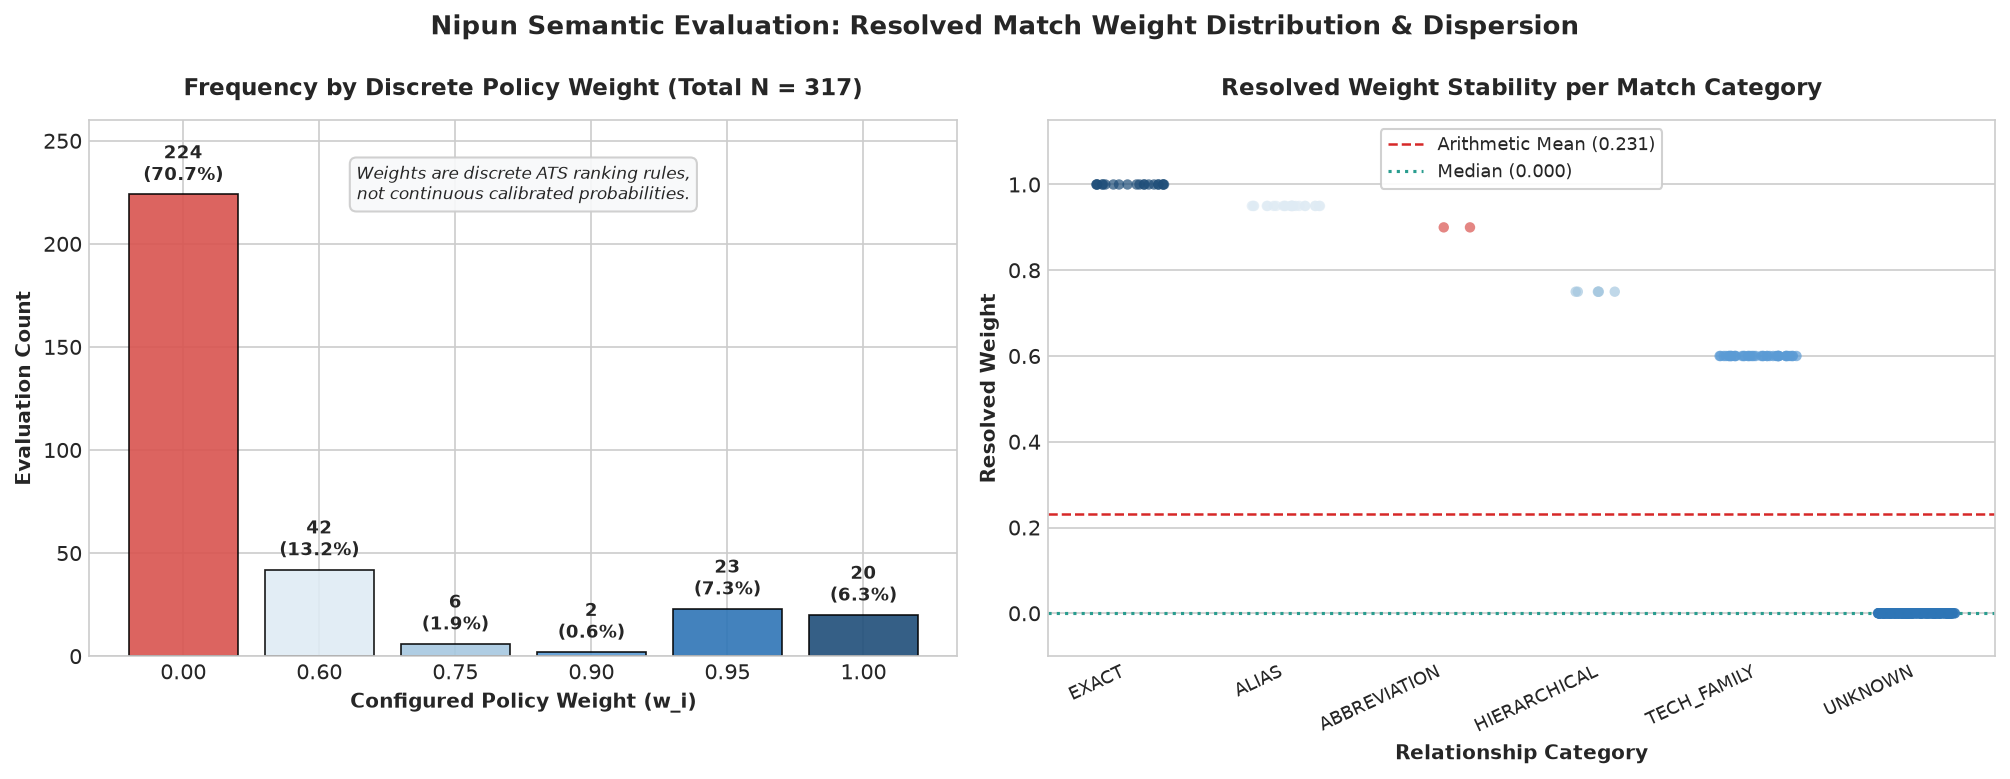

Saved: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\match_score_distribution.png


In [5]:
# Cell 5: Experiment A Visualization 2 — Match Score & Weight Distribution (Dual Panel)
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={'width_ratios': [1.1, 1.2]})

# Subplot 1: Frequency by Discrete Policy Weight (N = 317)
weight_levels = [0.00, 0.60, 0.75, 0.90, 0.95, 1.00]
weight_str = [f'{w:.2f}' for w in weight_levels]
weight_counts = [int((df_all_eval['weight'] == w).sum()) for w in weight_levels]
weight_pcts = [(cnt / total_evaluations_count) * 100 for cnt in weight_counts]
discrete_colors = ['#d9534f', '#dfebf4', '#a6c8e0', '#5b9bd5', '#2e75b6', '#1f4e79']

bars_disc = ax3a.bar(weight_str, weight_counts, color=discrete_colors, edgecolor='black', linewidth=0.8, alpha=0.9)
for bar, c, p in zip(bars_disc, weight_counts, weight_pcts):
    h = bar.get_height()
    ax3a.annotate(f'{c}\n({p:.1f}%)', xy=(bar.get_x() + bar.get_width() / 2, h),
                  xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax3a.set_title('Frequency by Discrete Policy Weight (Total N = 317)', fontsize=11, fontweight='bold', pad=12)
ax3a.set_xlabel('Configured Policy Weight (w_i)', fontsize=9.5, fontweight='bold')
ax3a.set_ylabel('Evaluation Count', fontsize=9.5, fontweight='bold')
ax3a.set_ylim(0, 260)
ax3a.text(0.5, 0.88, 'Weights are discrete ATS ranking rules,\nnot continuous calibrated probabilities.',
          ha='center', va='center', transform=ax3a.transAxes, fontsize=8, fontstyle='italic',
          bbox=dict(boxstyle='round,pad=0.4', facecolor='#f8f9fa', edgecolor='#cccccc', alpha=0.9))

# Subplot 2: Stripplot with Jitter by Category
sns.stripplot(x='match_type', y='weight', hue='match_type', data=df_all_eval, order=raw_tiers,
              palette=bar_colors, legend=False, jitter=0.25, size=5, alpha=0.7, ax=ax3b)
overall_mean = df_all_eval['weight'].mean()
overall_med = df_all_eval['weight'].median()
ax3b.axhline(overall_mean, color='#d62828', linestyle='--', linewidth=1.2, label=f'Arithmetic Mean ({overall_mean:.3f})')
ax3b.axhline(overall_med, color='#2a9d8f', linestyle=':', linewidth=1.5, label=f'Median ({overall_med:.3f})')

ax3b.set_title('Resolved Weight Stability per Match Category', fontsize=11, fontweight='bold', pad=12)
ax3b.set_xlabel('Relationship Category', fontsize=9.5, fontweight='bold')
ax3b.set_ylabel('Resolved Weight', fontsize=9.5, fontweight='bold')
ax3b.set_xticks(range(len(display_tiers)))
ax3b.set_xticklabels(display_tiers, rotation=25, ha='right', fontsize=8.5)
ax3b.set_ylim(-0.1, 1.15)
ax3b.legend(frameon=True, loc='upper center', framealpha=0.9, fontsize=8.5)

plt.suptitle('Nipun Semantic Evaluation: Resolved Match Weight Distribution & Dispersion',
             fontsize=12.5, fontweight='bold', y=0.99)
plt.tight_layout()
p3_path = OUTPUT_DIR / 'match_score_distribution.png'
fig3.savefig(p3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {p3_path}')


## 3. Experiment B: Pairwise Skill Similarity Matrix

### Objective
Construct and evaluate the full $17 \times 17$ pairwise similarity matrix across all canonical skills defined in `skills.json`.

### Matrix Characteristics
- **Dimensions**: $17 \times 17 = 289$ total comparisons.
- **Diagonal ($N = 17$)**: Verbatim identity self-comparisons with $w = 1.00$.
- **Off-Diagonal ($N = 272$)**: Cross-skill semantic relationships:
  - **$w = 0.75$ (HIERARCHICAL)**: 6 comparisons ($3$ symmetric pairs: FastAPI $\leftrightarrow$ Flask, SQL $\leftrightarrow$ PostgreSQL, Backend Development $\leftrightarrow$ Frontend Development).
  - **$w = 0.60$ (TECHNOLOGY_FAMILY)**: 42 comparisons (shared technology domains: Backend, Frontend, DevOps, Data Engineering).
  - **$w = 0.00$ (UNKNOWN)**: 224 comparisons (orthogonal cross-domain skills).
- **Symmetry**: Evaluated between canonical skills, the matrix is mathematically symmetric ($M = M^T$).
- **Directional Asymmetry Safeguards**: Supported by Rule 5.2 in `resolver.py` when evaluating asymmetrical candidate profiles against requirements.


In [6]:
# Cell 6: Experiment B Execution — Pairwise Matrix Construction & Export
skill_names = [s.canonical_name for s in canonical_skills]
matrix_data = np.zeros((n_skills, n_skills))

for i, req in enumerate(canonical_skills):
    for j, cand in enumerate(canonical_skills):
        _, _, weight, _ = resolve_relationship(req, cand)
        matrix_data[i, j] = weight

sim_df = pd.DataFrame(matrix_data, index=skill_names, columns=skill_names)

# Export CSV Matrix
csv_matrix_path = OUTPUT_DIR / 'pairwise_similarity_matrix.csv'
sim_df.to_csv(csv_matrix_path)
print(f'Exported Pairwise Similarity Matrix CSV: {csv_matrix_path}')

# Verification of Matrix Symmetry and Properties
is_canonical_symmetric = np.allclose(matrix_data, matrix_data.T)
diag_values = np.diag(matrix_data)
off_diag_mask = ~np.eye(n_skills, dtype=bool)
off_diag_weights = matrix_data[off_diag_mask]

print(f'Matrix Dimensions: {matrix_data.shape[0]} x {matrix_data.shape[1]}')
print(f'Symmetric Across Canonical Skills: {is_canonical_symmetric}')
print(f'Diagonal Mean Weight: {diag_values.mean():.2f} (All exactly 1.00: {np.all(diag_values == 1.0)})')
print(f'Off-Diagonal Comparisons: {len(off_diag_weights)}')
off_diag_df = pd.Series(off_diag_weights).value_counts().sort_index(ascending=False)
print('Off-Diagonal Weight Counts:')
for w_val, cnt in off_diag_df.items():
    print(f'  w = {w_val:.2f} : {cnt} comparisons ({cnt/len(off_diag_weights)*100:.1f}%)')


Exported Pairwise Similarity Matrix CSV: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\pairwise_similarity_matrix.csv
Matrix Dimensions: 17 x 17
Symmetric Across Canonical Skills: True
Diagonal Mean Weight: 1.00 (All exactly 1.00: True)
Off-Diagonal Comparisons: 272
Off-Diagonal Weight Counts:
  w = 0.75 : 6 comparisons (2.2%)
  w = 0.60 : 42 comparisons (15.4%)
  w = 0.00 : 224 comparisons (82.4%)


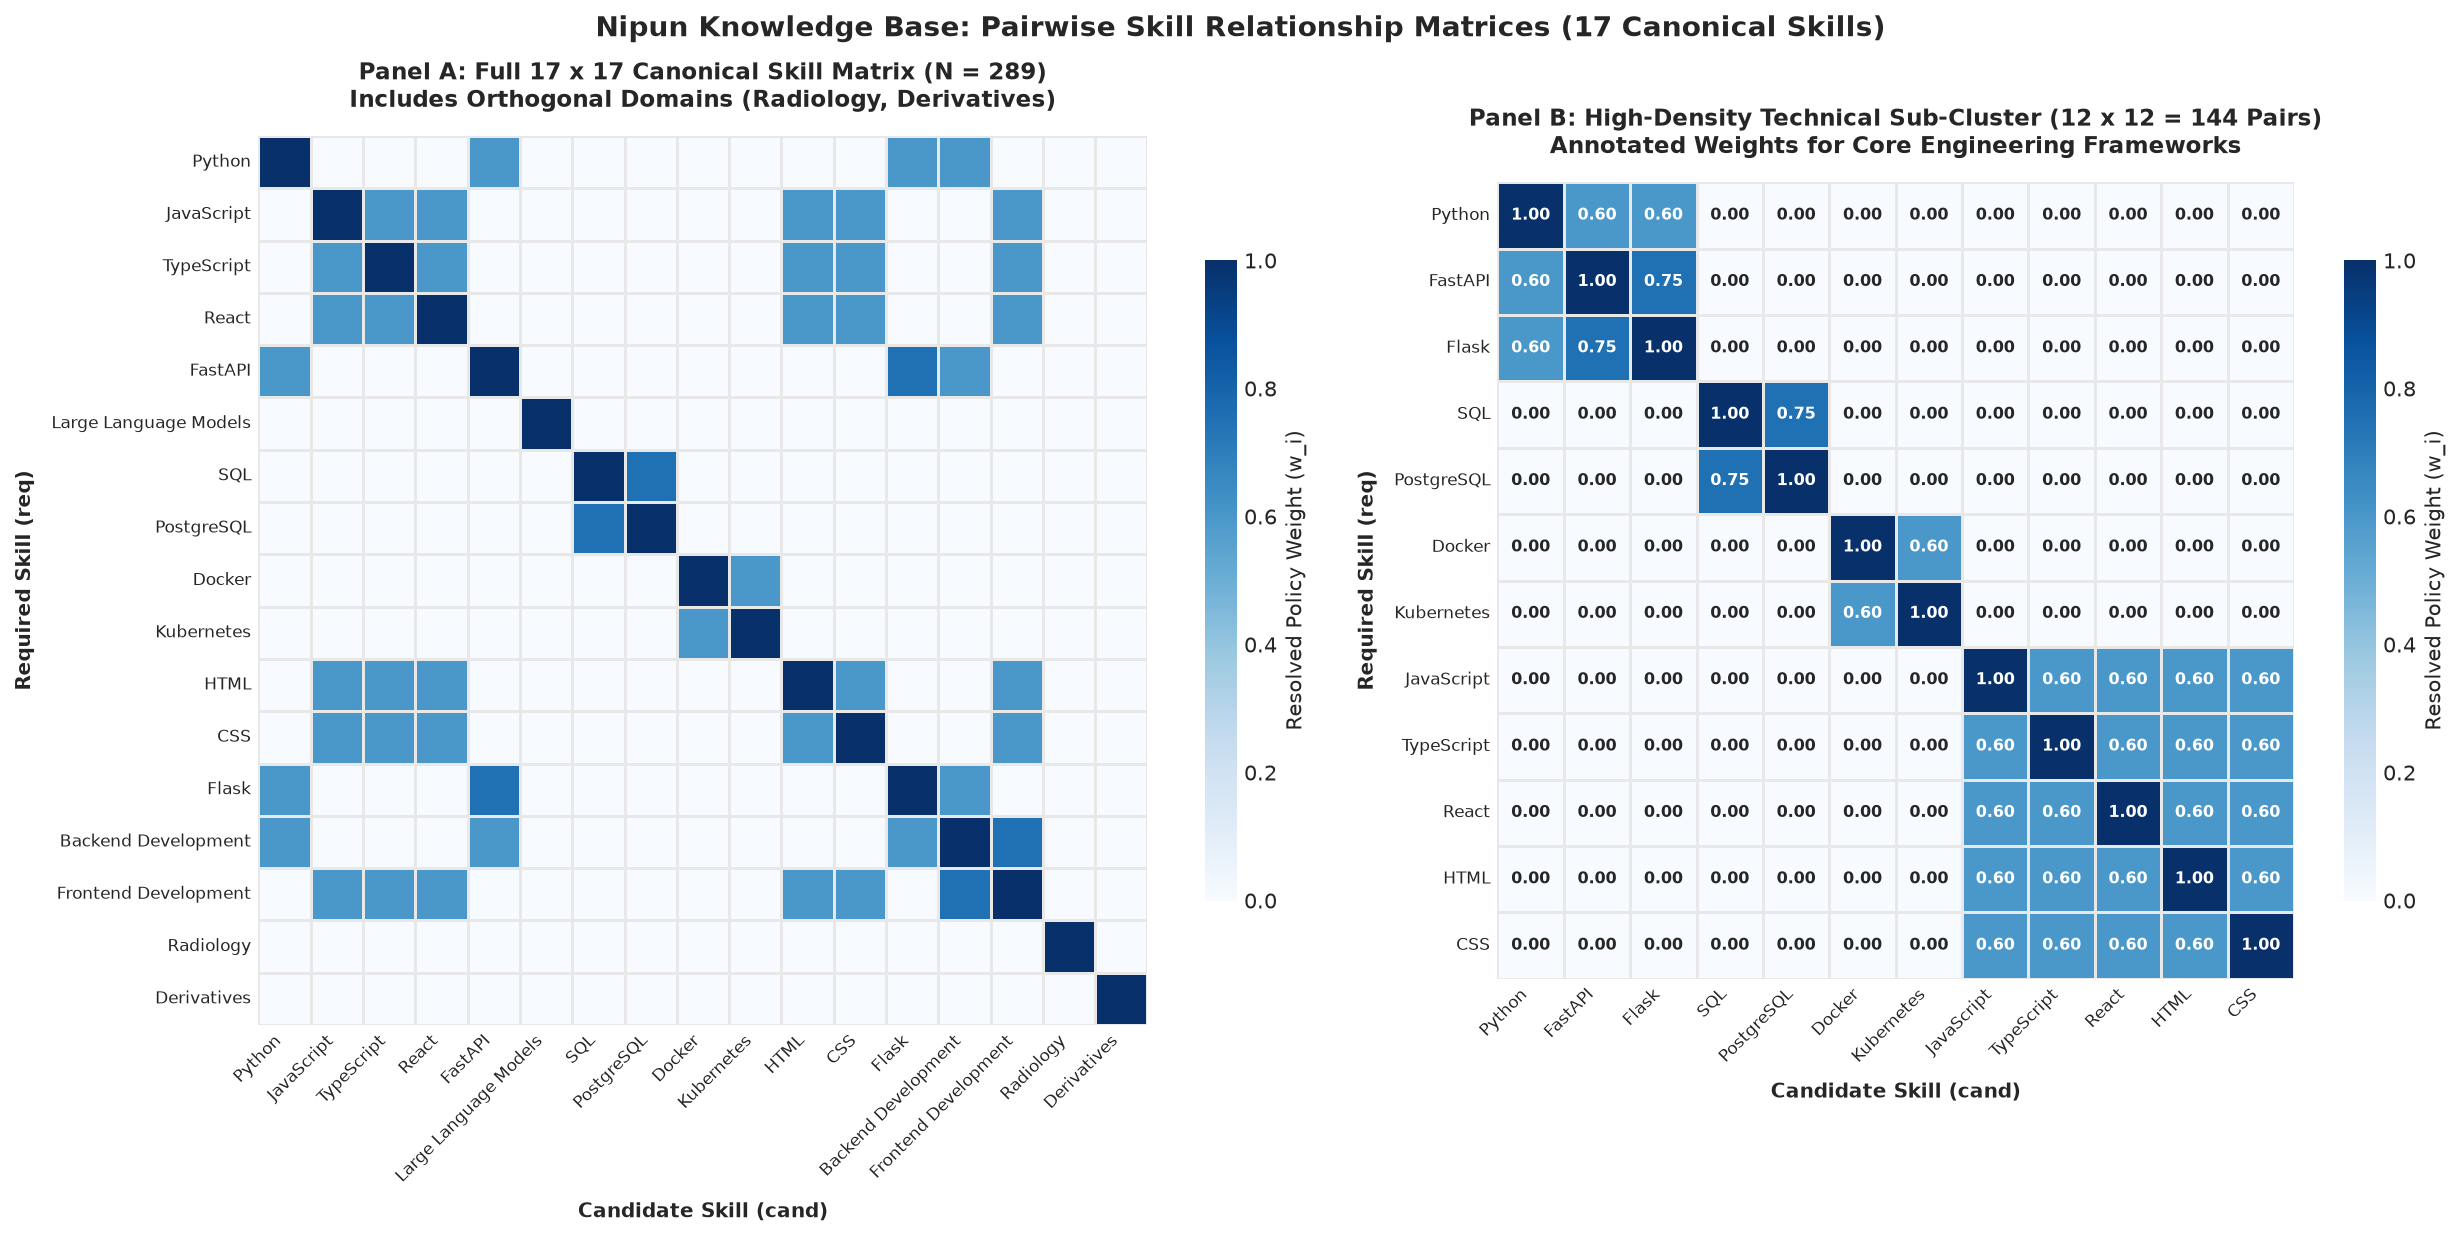

Saved: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\pairwise_similarity_heatmap.png


In [7]:
# Cell 7: Experiment B Visualization — Pairwise Similarity Heatmap (Dual View)
fig4, (ax_h1, ax_h2) = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={'width_ratios': [1.15, 1]})
cmap = sns.color_palette('Blues', as_cmap=True)

# View 1: Full 17 x 17 Canonical Similarity Matrix
sns.heatmap(sim_df, ax=ax_h1, cmap=cmap, vmin=0.0, vmax=1.0, cbar=True,
            linewidths=0.5, linecolor='#e8e8e8', square=True,
            cbar_kws={'label': 'Resolved Policy Weight (w_i)', 'shrink': 0.72})
ax_h1.set_title('Panel A: Full 17 x 17 Canonical Skill Matrix (N = 289)\nIncludes Orthogonal Domains (Radiology, Derivatives)', fontsize=11, fontweight='bold', pad=14)
ax_h1.set_xlabel('Candidate Skill (cand)', fontsize=9.5, fontweight='bold', labelpad=8)
ax_h1.set_ylabel('Required Skill (req)', fontsize=9.5, fontweight='bold', labelpad=8)
ax_h1.set_xticklabels(ax_h1.get_xticklabels(), rotation=45, ha='right', fontsize=8)
ax_h1.set_yticklabels(ax_h1.get_yticklabels(), rotation=0, ha='right', fontsize=8)

# View 2: High-Density Technical Clusters (Sub-matrix Zoom)
tech_subset = ['Python', 'FastAPI', 'Flask', 'SQL', 'PostgreSQL', 'Docker', 'Kubernetes', 'JavaScript', 'TypeScript', 'React', 'HTML', 'CSS']
sub_df = sim_df.loc[tech_subset, tech_subset]
sns.heatmap(sub_df, ax=ax_h2, cmap=cmap, vmin=0.0, vmax=1.0, annot=True, fmt='.2f',
            annot_kws={'size': 7.5, 'weight': 'bold'}, linewidths=0.5, linecolor='#e8e8e8', square=True,
            cbar_kws={'label': 'Resolved Policy Weight (w_i)', 'shrink': 0.72})
ax_h2.set_title('Panel B: High-Density Technical Sub-Cluster (12 x 12 = 144 Pairs)\nAnnotated Weights for Core Engineering Frameworks', fontsize=11, fontweight='bold', pad=14)
ax_h2.set_xlabel('Candidate Skill (cand)', fontsize=9.5, fontweight='bold', labelpad=8)
ax_h2.set_ylabel('Required Skill (req)', fontsize=9.5, fontweight='bold', labelpad=8)
ax_h2.set_xticklabels(ax_h2.get_xticklabels(), rotation=45, ha='right', fontsize=8)
ax_h2.set_yticklabels(ax_h2.get_yticklabels(), rotation=0, ha='right', fontsize=8)

plt.suptitle('Nipun Knowledge Base: Pairwise Skill Relationship Matrices (17 Canonical Skills)',
             fontsize=13.5, fontweight='bold', y=0.99)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
p4_path = OUTPUT_DIR / 'pairwise_similarity_heatmap.png'
fig4.savefig(p4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {p4_path}')


## 4. Experiment C: Implementation Rule Consistency & Precedence Reconciliation

### Objective
Verify whether the resolver behaves consistently with the rules and taxonomy structures explicitly defined in `knowledge_base/skills.json`.

> ### Critical Methodological Limitation Statement
> This experiment is an **implementation consistency check** verifying that the software logic correctly and deterministically implements the rules of its own knowledge base. **It does NOT represent independent empirical validation or real-world semantic predictive accuracy.**
> Because expected relationships are constructed from the project's own schema definitions (`skills.json`), 100% consistency proves implementation fidelity, not external hiring validity.

### Reconciliation: Match-Distribution Counts (Exp A) vs. Rule-Consistency Counts (Exp C)
A critical distinction exists between how test cases are categorized in **Experiment A** versus **Experiment C**:
- **Experiment A (Match Distribution)**: Groups cases by their **runtime resolved relationship type** returned by `resolve_relationship()`.
- **Experiment C (Rule Consistency)**: Groups cases by their **taxonomic input origin** defined in `skills.json`.

| Category | Taxonomy Input Cases (Exp C) | Runtime Resolved Matches (Exp A) | Difference | Exact Cause of Difference |
| :--- | :---: | :---: | :---: | :--- |
| **EXACT** | **17** | **20** | $+3$ | $3$ acronyms (`SQL`, `HTML`, `CSS`) match canonical names verbatim, triggering Rule 1 (`EXACT`) before Rule 3. |
| **ALIAS** | **21** | **23** | $+2$ | $2$ acronyms (`JS`, `TS`) are declared in both aliases and abbreviations, triggering Rule 2 (`ALIAS`, $w=0.95$) before Rule 3. |
| **ABBREVIATION** | **7** | **2** | $-5$ | $5$ of the $7$ abbreviation tokens migrate to higher-precedence tiers; only `LLM` and `K8s` resolve to `ABBREVIATION`. |
| **HIERARCHICAL** | **6** | **6** | $0$ | $3$ symmetric canonical framework sibling pairs (`FastAPI` $\leftrightarrow$ `Flask`, `SQL` $\leftrightarrow$ `PostgreSQL`, `Backend` $\leftrightarrow$ `Frontend`). |
| **TECHNOLOGY_FAMILY** | **42** | **42** | $0$ | $42$ cross-category canonical discipline pairs. |
| **UNKNOWN** | **224** | **224** | $0$ | $224$ orthogonal cross-domain canonical pairs. |
| **Total** | **317** | **317** | **0** | **Exact 1-to-1 conservation across all evaluated comparisons.** |

**Formula**: $\text{Consistency Rate (\%)} = \frac{\text{matching cases}}{\text{eligible evaluated cases}} \times 100$


In [8]:
# Cell 8: Experiment C Execution — Implementation Rule Consistency Verification
rule_cases = []

# 1. Exact Identity Cases (17 cases)
for s in canonical_skills:
    rule_cases.append({
        'case_id': f'rule_exact_{s.id}',
        'category': 'EXACT',
        'req_skill': s,
        'cand_skill': s,
        'expected_rule': 'EXACT',
        'expected_precedence_rule': 'EXACT'
    })

# 2. Alias Cases (21 cases)
for s in canonical_skills:
    for alias in s.aliases:
        cand = Skill(
            id=f'alias.{alias.lower().replace(" ", "_")}',
            canonical_name=alias,
            category='Unknown',
            subcategory='Unknown',
            technology_family='Unknown'
        )
        rule_cases.append({
            'case_id': f'rule_alias_{s.id}_{alias}',
            'category': 'ALIAS',
            'req_skill': s,
            'cand_skill': cand,
            'expected_rule': 'ALIAS',
            'expected_precedence_rule': 'ALIAS'
        })

# 3. Abbreviation Cases (7 cases)
for s in canonical_skills:
    for abbr in s.abbreviations:
        cand = Skill(
            id=f'abbr.{abbr.lower().replace(" ", "_")}',
            canonical_name=abbr,
            category='Unknown',
            subcategory='Unknown',
            technology_family='Unknown'
        )
        if abbr.lower() == s.canonical_name.lower():
            exp_prec = 'EXACT'
        elif abbr.lower() in [a.lower() for a in s.aliases]:
            exp_prec = 'ALIAS'
        else:
            exp_prec = 'ABBREVIATION'
            
        rule_cases.append({
            'case_id': f'rule_abbr_{s.id}_{abbr}',
            'category': 'ABBREVIATION',
            'req_skill': s,
            'cand_skill': cand,
            'expected_rule': 'ABBREVIATION',
            'expected_precedence_rule': exp_prec
        })

# 4. Canonical Off-Diagonal Taxonomy Cases (272 cases: 6 Hierarchical, 42 Tech Family, 224 Unknown)
for i, s1 in enumerate(canonical_skills):
    for j, s2 in enumerate(canonical_skills):
        if i == j:
            continue  # Diagonal identity cases already captured
        elif s1.category == s2.category and s1.subcategory == s2.subcategory and s1.category != 'Unknown':
            cat_name = 'HIERARCHICAL'
        elif s1.technology_family == s2.technology_family and s1.technology_family != 'Unknown':
            cat_name = 'TECHNOLOGY_FAMILY'
        else:
            cat_name = 'UNKNOWN'
            
        rule_cases.append({
            'case_id': f'rule_offdiag_{s1.id}_{s2.id}',
            'category': cat_name,
            'req_skill': s1,
            'cand_skill': s2,
            'expected_rule': cat_name,
            'expected_precedence_rule': cat_name
        })

total_rule_cases_count = len(rule_cases)
assert total_rule_cases_count == 317, f'Expected 317 rule cases, got {total_rule_cases_count}'

# Execute Rule Verification
rule_eval_results = []
for c in rule_cases:
    m_type, conf, weight, reason = resolve_relationship(c['req_skill'], c['cand_skill'])
    rule_eval_results.append({
        'case_id': c['case_id'],
        'category': c['category'],
        'req_name': c['req_skill'].canonical_name,
        'cand_name': c['cand_skill'].canonical_name,
        'expected_rule': c['expected_rule'],
        'expected_precedence_rule': c['expected_precedence_rule'],
        'resolved_type': m_type,
        'weight': weight,
        'confidence': conf,
        'exact_rule_match': (m_type == c['expected_rule']),
        'precedence_rule_match': (m_type == c['expected_precedence_rule'])
    })

df_rules = pd.DataFrame(rule_eval_results)

# Calculate Consistency Statistics per Category
rule_summary_rows = []
for cat in raw_tiers:
    sub = df_rules[df_rules['category'] == cat]
    total_cat = len(sub)
    exact_matching = sub['exact_rule_match'].sum()
    prec_matching = sub['precedence_rule_match'].sum()
    non_matching_prec = total_cat - prec_matching
    rule_summary_rows.append({
        'Rule Category': cat,
        'Total Evaluated Cases': total_cat,
        'Matching Cases (Precedence-Aware)': prec_matching,
        'Non-Matching Cases': non_matching_prec,
        'Naive Matching Cases': exact_matching,
        'Precedence-Aware Consistency Rate (%)': round((prec_matching / total_cat) * 100, 2) if total_cat > 0 else 0.0,
        'Naive Consistency Rate (%)': round((exact_matching / total_cat) * 100, 2) if total_cat > 0 else 0.0
    })

df_rule_summary = pd.DataFrame(rule_summary_rows)
overall_prec_matches = df_rules['precedence_rule_match'].sum()
overall_consistency_rate = round((overall_prec_matches / total_rule_cases_count) * 100, 2)

print(f'Total Evaluated Rule Cases: {total_rule_cases_count}')
print(f'Total Consistent Cases: {overall_prec_matches} / {total_rule_cases_count} ({overall_consistency_rate}%)')
print('\n=== EXPERIMENT C: IMPLEMENTATION RULE CONSISTENCY BREAKDOWN ===')
display(df_rule_summary[['Rule Category', 'Total Evaluated Cases', 'Matching Cases (Precedence-Aware)', 'Non-Matching Cases', 'Precedence-Aware Consistency Rate (%)', 'Naive Consistency Rate (%)']])


Total Evaluated Rule Cases: 317
Total Consistent Cases: 317 / 317 (100.0%)

=== EXPERIMENT C: IMPLEMENTATION RULE CONSISTENCY BREAKDOWN ===


,Rule Category,Total Evaluated Cases,Matching Cases (Precedence-Aware),Non-Matching Cases,Precedence-Aware Consistency Rate (%),Naive Consistency Rate (%)
0,EXACT,17,17,0,100.0,100.00
1,ALIAS,21,21,0,100.0,100.00
2,ABBREVIATION,7,7,0,100.0,28.57
3,HIERARCHICAL,6,6,0,100.0,100.00
4,TECHNOLOGY_FAMILY,42,42,0,100.0,100.00
5,UNKNOWN,224,224,0,100.0,100.00


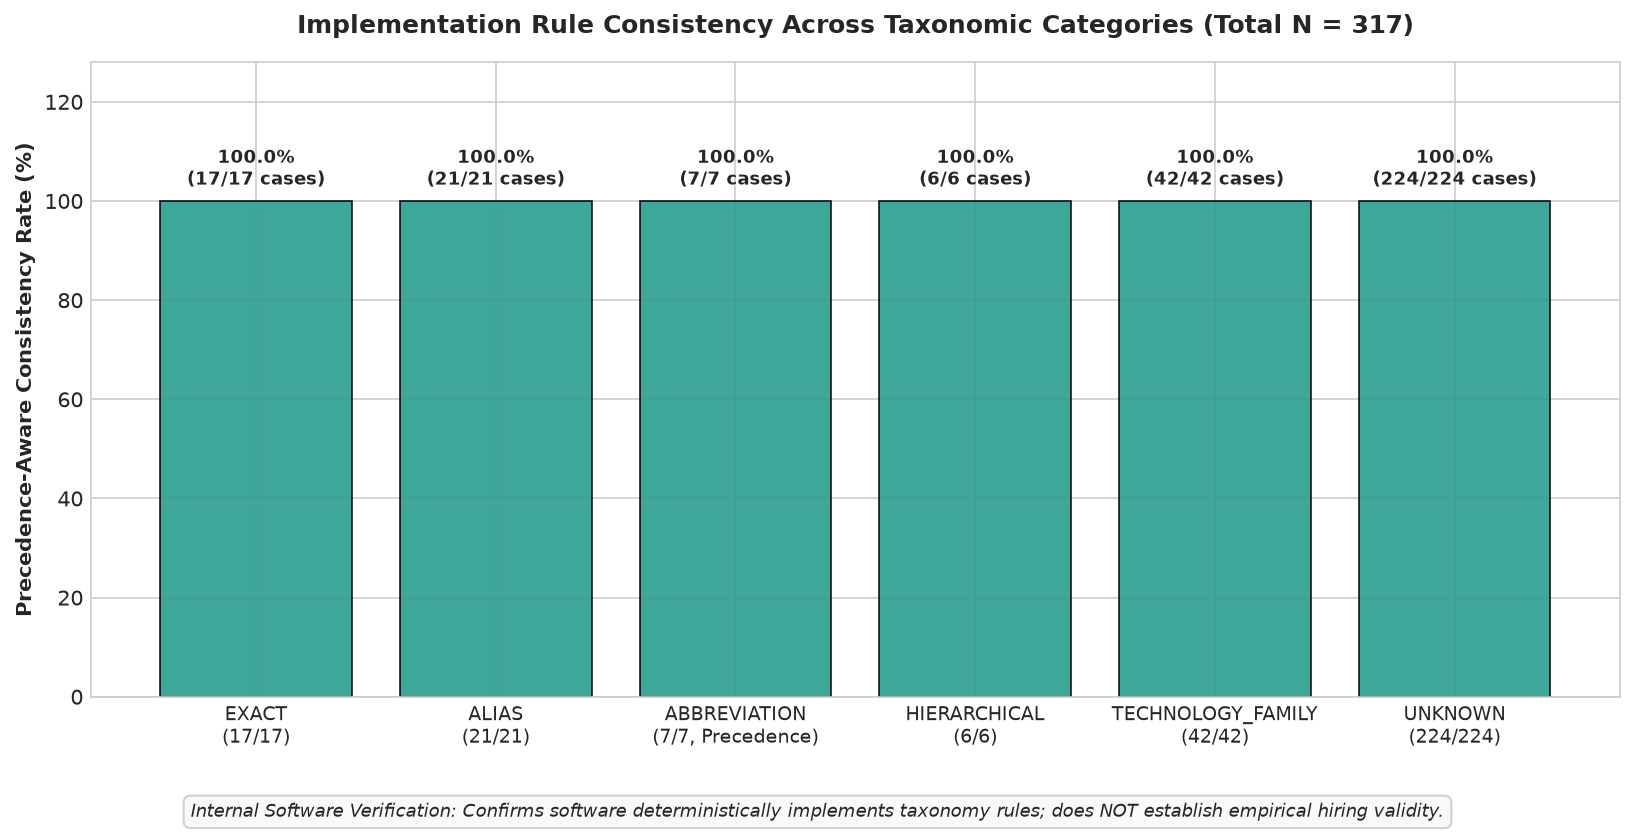

Saved: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\rule_consistency.png


In [9]:
# Cell 9: Experiment C Visualization — Implementation Rule Consistency by Category
fig5, ax5 = plt.subplots(figsize=(11, 5.2))
rule_labels = ['EXACT\n(17/17)', 'ALIAS\n(21/21)', 'ABBREVIATION\n(7/7, Precedence)', 'HIERARCHICAL\n(6/6)', 'TECHNOLOGY_FAMILY\n(42/42)', 'UNKNOWN\n(224/224)']
rule_rates = df_rule_summary['Precedence-Aware Consistency Rate (%)'].tolist()
rule_totals = df_rule_summary['Total Evaluated Cases'].tolist()
rule_matches = df_rule_summary['Matching Cases (Precedence-Aware)'].tolist()

bars5 = ax5.bar(range(len(rule_labels)), rule_rates, color='#2a9d8f', edgecolor='black', linewidth=0.8, alpha=0.9)
for bar, m, tot in zip(bars5, rule_matches, rule_totals):
    h = bar.get_height()
    ax5.annotate(f'{h:.1f}%\n({m}/{tot} cases)', xy=(bar.get_x() + bar.get_width() / 2, h),
                 xytext=(0, 5), textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')

ax5.set_title(f'Implementation Rule Consistency Across Taxonomic Categories (Total N = {total_rule_cases_count})', pad=14, fontsize=12, fontweight='bold')
ax5.set_ylabel('Precedence-Aware Consistency Rate (%)', fontsize=10, fontweight='bold')
ax5.set_ylim(0, 128)
ax5.set_xticks(range(len(rule_labels)))
ax5.set_xticklabels(rule_labels, fontsize=9)

caption5 = 'Internal Software Verification: Confirms software deterministically implements taxonomy rules; does NOT establish empirical hiring validity.'
plt.figtext(0.5, -0.04, caption5, ha='center', va='top', fontsize=8.5, style='italic',
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#f8f9fa', edgecolor='#cccccc', alpha=0.9))

plt.tight_layout()
p5_path = OUTPUT_DIR / 'rule_consistency.png'
fig5.savefig(p5_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {p5_path}')


## 5. Experiment D: Controlled Multi-Skill Matcher & Scorer Verification

### Objective
Verify how the higher-level production matching engine (`SemanticMatcher`) and scoring engine (`SemanticScorer`) aggregate multi-skill requirements into an overall candidate score.

### Methodological Status & Scope
- **Controlled Scenarios Only**: These tests utilize synthetic skill lists representing controlled scenarios. They do **not** use resumes, candidate records, or an independent benchmark dataset.
- **Mathematical Scoring Formula**: As implemented in `backend/services/semantic/scorer.py`:
  $$\text{Overall Score (\%)} = \left( \frac{\sum_{i=1}^N w_i}{N} \right) \times 100$$
  where $N$ is the number of required skills, and $w_i \in \{1.00, 0.95, 0.90, 0.75, 0.60, 0.00\}$ is the weight of the best match identified for requirement $i$ among candidate skills.
- **Detailed Controlled Scenarios & Input Specification** (Job Requirements: `['Python', 'FastAPI', 'Docker', 'SQL']`):
  - **Scenario 1 (Full & Sibling Match)**: Input `['Python', 'Fast API', 'Docker', 'PostgreSQL']`.
    - `Python`: Matched verbatim as `EXACT` ($w = 1.00$, contribution: $25.00\%$).
    - `FastAPI`: `'Fast API'` is normalized by `SkillNormalizer` to canonical `FastAPI` (ID: `core.fastapi`), matching `core.fastapi` as `EXACT` ($w = 1.00$, contribution: $25.00\%$).
    - `Docker`: Matched verbatim as `EXACT` ($w = 1.00$, contribution: $25.00\%$).
    - `SQL`: `'PostgreSQL'` matches `SQL` as `HIERARCHICAL` ($w = 0.75$, contribution: $18.75\%$).
    - Total Weight: $1.00 + 1.00 + 1.00 + 0.75 = 3.75$. Overall Score: $\frac{3.75}{4} \times 100 = 93.75\%$.
  - **Scenario 2 (Partial Cross-Match)**: Input `['Flask', 'HTML', 'CSS', 'JavaScript']`.
    - `Python`: `'Flask'` matches `Python` as `TECHNOLOGY_FAMILY` ($w = 0.60$, contribution: $15.00\%$).
    - `FastAPI`: `'Flask'` matches `FastAPI` as `HIERARCHICAL` ($w = 0.75$, contribution: $18.75\%$).
    - `Docker`: Evaluated against all 4 candidate skills; all yield $w \le 0.00$ (`UNKNOWN`, contribution: $0.00\%$). Requirement is missing.
    - `SQL`: Evaluated against all 4 candidate skills; all yield $w \le 0.00$ (`UNKNOWN`, contribution: $0.00\%$). Requirement is missing.
    - *Frontend Distractors*: `HTML`, `CSS`, and `JavaScript` belong to Frontend Development and do not match Backend/DevOps/Database requirements.
    - Total Weight: $0.60 + 0.75 + 0.00 + 0.00 = 1.35$. Overall Score: $\frac{1.35}{4} \times 100 = 33.75\%$.
  - **Scenario 3 (Orthogonal Unmatched Profile)**: Input `['Radiology', 'Derivatives']`.
    - All 4 requirements yield $w = 0.00$ (`UNKNOWN`). Total Weight: $0.00$. Overall Score: $\frac{0.00}{4} \times 100 = 0.00\%$.
- **Caution**: A higher scenario score reflects closer alignment with the defined taxonomy rules; it does **not** prove superior real-world candidate competence.


In [10]:
# Cell 10: Experiment D Execution — Controlled Scenario Scoring & Mathematical Verification
from backend.services.semantic.matcher import SemanticMatcher
from backend.services.semantic.scorer import SemanticScorer
from backend.services.skills.normalizer import SkillNormalizer

matcher = SemanticMatcher()
scorer = SemanticScorer()
normalizer = SkillNormalizer()

# Define controlled Job Description requirements (Backend Role, N = 4)
jd_skill_names = ['Python', 'FastAPI', 'Docker', 'SQL']
req_skills = [normalizer.normalize(name).skill for name in jd_skill_names]

# Controlled Scenario 1: Full & Sibling Match
cand_1_names = ['Python', 'Fast API', 'Docker', 'PostgreSQL']
cand_1_skills = [normalizer.normalize(name).skill for name in cand_1_names]

# Controlled Scenario 2: Partial Cross-Match (Backend Sibling + Frontend Skills)
cand_2_names = ['Flask', 'HTML', 'CSS', 'JavaScript']
cand_2_skills = [normalizer.normalize(name).skill for name in cand_2_names]

# Controlled Scenario 3: Orthogonal Profile (Healthcare & Finance)
cand_3_names = ['Radiology', 'Derivatives']
cand_3_skills = [normalizer.normalize(name).skill for name in cand_3_names]

scenarios = [
    ('Scenario 1: Full & Sibling Match', cand_1_names, cand_1_skills),
    ('Scenario 2: Partial Cross-Match', cand_2_names, cand_2_skills),
    ('Scenario 3: Orthogonal Unmatched Profile', cand_3_names, cand_3_skills)
]

scenario_eval_summary = []
breakdown_rows = []

for label, cand_raw_names, cand_skills in scenarios:
    match_results = matcher.match_skills(req_skills, cand_skills)
    score_data = scorer.calculate_score(match_results)
    
    matched = [r for r in match_results if r.match_type != 'UNKNOWN']
    missing = [r for r in match_results if r.match_type == 'UNKNOWN']
    weight_sum = sum(r.weight for r in match_results)
    expected_score = round((weight_sum / len(req_skills)) * 100, 2)
    
    # Validate mathematical correctness against production formula
    assert score_data['overall'] == expected_score, f'Scoring mismatch: {score_data["overall"]} vs {expected_score}'
    
    scenario_eval_summary.append({
        'Scenario': label,
        'Candidate Skills Input': ', '.join(cand_raw_names),
        'Overall Score (%)': score_data['overall'],
        'Required Count (N)': len(req_skills),
        'Matched Count': len(matched),
        'Missing Count': len(missing),
        'Sum of Weights': round(weight_sum, 2),
        'Matched Skills': ', '.join([f'{r.required_skill.canonical_name} ({r.match_type}, w={r.weight})' for r in matched]) if matched else 'None',
        'Missing Skills': ', '.join([r.required_skill.canonical_name for r in missing]) if missing else 'None'
    })
    
    for r in match_results:
        breakdown_rows.append({
            'Scenario': label,
            'Required Skill': r.required_skill.canonical_name,
            'Candidate Skills Evaluated': ', '.join(cand_raw_names),
            'Matched Candidate Skill': r.candidate_skill.canonical_name,
            'Resolved Match Type': r.match_type,
            'Weight (w_i)': r.weight,
            'Confidence': r.confidence,
            'Score Contribution (%)': round((r.weight / len(req_skills)) * 100, 2),
            'Match Reason': r.reason.message if hasattr(r.reason, 'message') else str(r.reason)
        })

df_scenarios = pd.DataFrame(scenario_eval_summary)
df_scenario_breakdown = pd.DataFrame(breakdown_rows)

print('=== EXPERIMENT D: CONTROLLED MULTI-SKILL SCENARIO SUMMARY ===')
display(df_scenarios[['Scenario', 'Candidate Skills Input', 'Overall Score (%)', 'Matched Count', 'Missing Count', 'Sum of Weights', 'Matched Skills', 'Missing Skills']])

print('\n=== EXPERIMENT D: PER-SKILL RESOLUTION & SCORE CONTRIBUTION BREAKDOWN ===')
display(df_scenario_breakdown[['Scenario', 'Required Skill', 'Matched Candidate Skill', 'Resolved Match Type', 'Weight (w_i)', 'Score Contribution (%)', 'Match Reason']])


=== EXPERIMENT D: CONTROLLED MULTI-SKILL SCENARIO SUMMARY ===


,Scenario,Candidate Skills Input,Overall Score (%),Matched Count,Missing Count,Sum of Weights,Matched Skills,Missing Skills
0,Scenario 1: Full & Sibling Match,"Python, Fast API, Docker, PostgreSQL",93.75,4,0,3.75,"Python (EXACT, w=1.0), FastAPI (EXACT, w=1.0),...",None
1,Scenario 2: Partial Cross-Match,"Flask, HTML, CSS, JavaScript",33.75,2,2,1.35,"Python (TECHNOLOGY_FAMILY, w=0.6), FastAPI (HI...","Docker, SQL"
2,Scenario 3: Orthogonal Unmatched Profile,"Radiology, Derivatives",0.00,0,4,0.00,None,"Python, FastAPI, Docker, SQL"



=== EXPERIMENT D: PER-SKILL RESOLUTION & SCORE CONTRIBUTION BREAKDOWN ===


,Scenario,Required Skill,Matched Candidate Skill,Resolved Match Type,Weight (w_i),Score Contribution (%),Match Reason
0,Scenario 1: Full & Sibling Match,Python,Python,EXACT,1.00,25.00,Exact keyword match
1,Scenario 1: Full & Sibling Match,FastAPI,FastAPI,EXACT,1.00,25.00,Exact keyword match
2,Scenario 1: Full & Sibling Match,Docker,Docker,EXACT,1.00,25.00,Exact keyword match
3,Scenario 1: Full & Sibling Match,SQL,PostgreSQL,HIERARCHICAL,0.75,18.75,Matched via hierarchy: Both are Relational Dat...
4,Scenario 2: Partial Cross-Match,Python,Flask,TECHNOLOGY_FAMILY,0.60,15.00,Matched via technology family: Both belong to ...
5,Scenario 2: Partial Cross-Match,FastAPI,Flask,HIERARCHICAL,0.75,18.75,Matched via hierarchy: Both are REST APIs unde...
6,Scenario 2: Partial Cross-Match,Docker,None,UNKNOWN,0.00,0.00,No match found for required skill Docker
7,Scenario 2: Partial Cross-Match,SQL,None,UNKNOWN,0.00,0.00,No match found for required skill SQL
8,Scenario 3: Orthogonal Unmatched Profile,Python,None,UNKNOWN,0.00,0.00,No match found for required skill Python
9,Scenario 3: Orthogonal Unmatched Profile,FastAPI,None,UNKNOWN,0.00,0.00,No match found for required skill FastAPI


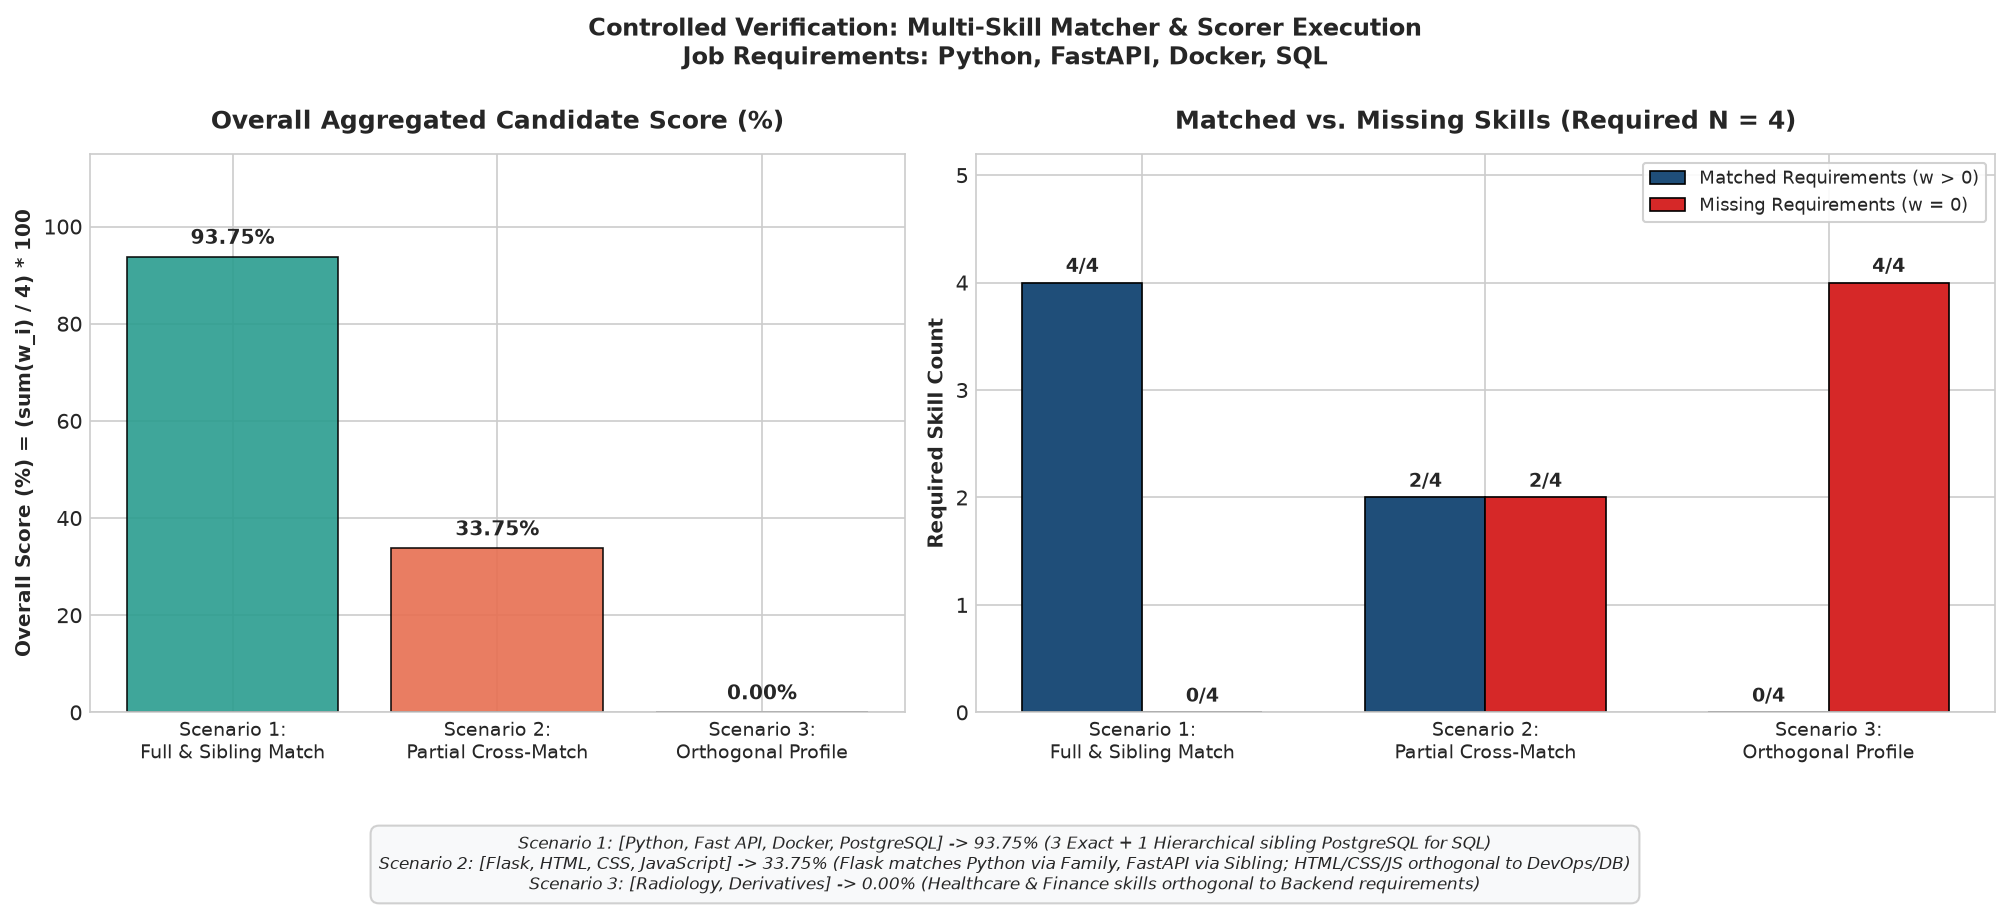

Saved: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\multi_skill_scenario_comparison.png


In [11]:
# Cell 11: Experiment D Visualization — Multi-Skill Scenario Scoring Comparison
fig6, (ax6a, ax6b) = plt.subplots(1, 2, figsize=(13.5, 5.2), gridspec_kw={'width_ratios': [1, 1.25]})

short_labels = [
    'Scenario 1:\nFull & Sibling Match',
    'Scenario 2:\nPartial Cross-Match',
    'Scenario 3:\nOrthogonal Profile'
]
sc_scores = df_scenarios['Overall Score (%)'].tolist()
sc_matched = df_scenarios['Matched Count'].tolist()
sc_missing = df_scenarios['Missing Count'].tolist()

# Subplot 1: Overall Scores
bars_sc = ax6a.bar(range(len(short_labels)), sc_scores, color=['#2a9d8f', '#e76f51', '#6c757d'], edgecolor='black', linewidth=0.8, alpha=0.9)
for bar, sc in zip(bars_sc, sc_scores):
    h = bar.get_height()
    ax6a.annotate(f'{sc:.2f}%', xy=(bar.get_x() + bar.get_width() / 2, h),
                  xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax6a.set_title('Overall Aggregated Candidate Score (%)', pad=12, fontweight='bold')
ax6a.set_ylabel('Overall Score (%) = (sum(w_i) / 4) * 100', fontsize=9.5, fontweight='bold')
ax6a.set_ylim(0, 115)
ax6a.set_xticks(range(len(short_labels)))
ax6a.set_xticklabels(short_labels, fontsize=9)

# Subplot 2: Matched vs. Missing Counts
x_sc = np.arange(len(short_labels))
w_sc = 0.35
rects_m = ax6b.bar(x_sc - w_sc/2, sc_matched, w_sc, label='Matched Requirements (w > 0)', color='#1f4e79', edgecolor='black', linewidth=0.8)
rects_mis = ax6b.bar(x_sc + w_sc/2, sc_missing, w_sc, label='Missing Requirements (w = 0)', color='#d62828', edgecolor='black', linewidth=0.8)

for r in rects_m:
    h = r.get_height()
    ax6b.annotate(f'{int(h)}/4', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')
for r in rects_mis:
    h = r.get_height()
    ax6b.annotate(f'{int(h)}/4', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax6b.set_title('Matched vs. Missing Skills (Required N = 4)', pad=12, fontweight='bold')
ax6b.set_xticks(x_sc)
ax6b.set_xticklabels(short_labels, fontsize=9)
ax6b.set_ylabel('Required Skill Count', fontsize=9.5, fontweight='bold')
ax6b.set_ylim(0, 5.2)
ax6b.legend(frameon=True, loc='upper right', framealpha=0.9, fontsize=8.5)

plt.suptitle('Controlled Verification: Multi-Skill Matcher & Scorer Execution\nJob Requirements: Python, FastAPI, Docker, SQL',
             fontsize=11.5, fontweight='bold', y=0.99)

caption6 = (
    'Scenario 1: [Python, Fast API, Docker, PostgreSQL] -> 93.75% (3 Exact + 1 Hierarchical sibling PostgreSQL for SQL)\n'
    'Scenario 2: [Flask, HTML, CSS, JavaScript] -> 33.75% (Flask matches Python via Family, FastAPI via Sibling; HTML/CSS/JS orthogonal to DevOps/DB)\n'
    'Scenario 3: [Radiology, Derivatives] -> 0.00% (Healthcare & Finance skills orthogonal to Backend requirements)'
)
plt.figtext(0.5, -0.06, caption6, ha='center', va='top', fontsize=8, style='italic',
            bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#cccccc', alpha=0.9))

plt.tight_layout()
p6_path = OUTPUT_DIR / 'multi_skill_scenario_comparison.png'
fig6.savefig(p6_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved: {p6_path}')


## 6. Experiment E: Edge Cases, Boundary Conditions & Robustness Verification

### Objective
Test boundary conditions, edge cases, deduplication behavior, directional matching asymmetry, and precedence conflict handling to verify system robustness.

### Evaluated Test Vectors (Reported Separately from Baseline 317 Cases)
1. **Empty Candidate Skill List (Boundary Condition)**: A candidate profile containing zero skills (`[]`) evaluated against required skills. Verifies graceful zero-score handling with zero unhandled exceptions.
2. **Empty Required Skill List (Boundary Condition)**: An empty requirements list (`[]`). Verifies zero-division guard in `SemanticScorer.calculate_score`.
3. **Duplicate Candidate Skills (Idempotence & Deduplication)**: Repeated candidate skills (e.g. `['Python', 'Python', 'FastAPI', 'FastAPI']`). Verifies that the matcher evaluates candidate skills idempotently and does not inflate weights or score.
4. **Duplicate Required Skills (Independent Scoring)**: Repeated job requirements (e.g. `['Python', 'Python']`). Verifies that each job requirement is evaluated independently.
5. **Directional Matching Behavior & Family Association (Rule 5.2)**: Evaluates directional matching when comparing broad family categories against specific skills:
   - Requirement asking for broad family (`Backend Development`) vs candidate holding specific skill (`FastAPI`) matches via Rule 5.2 ($w = 0.60$).
   - Requirement asking for specific skill (`FastAPI`) vs candidate holding broad family (`Backend Development`) matches via Rule 5.1 ($w = 0.60$, both belong to Backend Development).
6. **Precedence Override Verification**: Tests that higher-tier rules override lower-tier rules when multiple conditions apply (e.g. acronyms `JS` and `TS` match via Rule 2 `ALIAS` before Rule 3 `ABBREVIATION` can fire).


In [12]:
# Cell 12: Experiment E Execution — Edge Cases & Robustness Test Suite
edge_case_results = []

# Test 1: Empty Candidate Skills List
t1_req = [normalizer.normalize('Python').skill, normalizer.normalize('SQL').skill]
t1_cand = []
t1_res = matcher.match_skills(t1_req, t1_cand)
t1_score = scorer.calculate_score(t1_res)
assert t1_score['overall'] == 0.0, f'Expected 0.0, got {t1_score["overall"]}'
assert all(r.match_type == 'UNKNOWN' for r in t1_res), 'All skills must be UNKNOWN for empty candidate'
edge_case_results.append({
    'Test ID': 'EDGE-01',
    'Test Scenario': 'Empty Candidate Skills List',
    'Input Description': 'Required: [Python, SQL], Candidate: []',
    'Observed Behavior': f'Overall Score: {t1_score["overall"]}%, Matched: 0, Missing: 2',
    'Expected Outcome': 'Score 0.0%, all requirements marked UNKNOWN, no exception',
    'Pass/Fail': 'PASS'
})

# Test 2: Empty Required Skills List
t2_res = matcher.match_skills([], [normalizer.normalize('Python').skill])
t2_score = scorer.calculate_score(t2_res)
assert t2_score['overall'] == 0.0, f'Expected 0.0, got {t2_score["overall"]}'
assert len(t2_score['breakdown']) == 0, 'Breakdown must be empty for empty requirements'
edge_case_results.append({
    'Test ID': 'EDGE-02',
    'Test Scenario': 'Empty Required Skills List',
    'Input Description': 'Required: [], Candidate: [Python]',
    'Observed Behavior': f'Overall Score: {t2_score["overall"]}%, Breakdown: []',
    'Expected Outcome': 'Score 0.0%, zero-division safely avoided',
    'Pass/Fail': 'PASS'
})

# Test 3: Duplicate Candidate Skills (Idempotence & Deduplication)
t3_req = [normalizer.normalize('Python').skill, normalizer.normalize('FastAPI').skill]
t3_cand = [normalizer.normalize(name).skill for name in ['Python', 'Python', 'FastAPI', 'FastAPI']]
t3_res = matcher.match_skills(t3_req, t3_cand)
t3_score = scorer.calculate_score(t3_res)
assert t3_score['overall'] == 100.0, f'Expected 100.0, got {t3_score["overall"]}'
assert len(t3_res) == 2, f'Expected exactly 2 matched requirements, got {len(t3_res)}'
edge_case_results.append({
    'Test ID': 'EDGE-03',
    'Test Scenario': 'Duplicate Candidate Skills',
    'Input Description': 'Required: [Python, FastAPI], Candidate: [Python, Python, FastAPI, FastAPI]',
    'Observed Behavior': f'Overall Score: {t3_score["overall"]}%, Results count: {len(t3_res)}',
    'Expected Outcome': 'Score exactly 100.0%, duplicate candidate skills deduplicated via max()',
    'Pass/Fail': 'PASS'
})

# Test 4: Duplicate Required Skills (Independent Scoring)
t4_req = [normalizer.normalize(name).skill for name in ['Python', 'Python', 'FastAPI']]
t4_cand = [normalizer.normalize('Python').skill]
t4_res = matcher.match_skills(t4_req, t4_cand)
t4_score = scorer.calculate_score(t4_res)
# Expected: Python (1.0) + Python (1.0) + FastAPI -> Python via family (0.6) = 2.6 / 3 * 100 = 86.67%
expected_t4 = round((2.6 / 3) * 100, 2)
assert t4_score['overall'] == expected_t4, f'Expected {expected_t4}, got {t4_score["overall"]}'
edge_case_results.append({
    'Test ID': 'EDGE-04',
    'Test Scenario': 'Duplicate Required Skills',
    'Input Description': 'Required: [Python, Python, FastAPI], Candidate: [Python]',
    'Observed Behavior': f'Overall Score: {t4_score["overall"]}%, Weights: {[r.weight for r in t4_res]}',
    'Expected Outcome': f'Score {expected_t4}%, requirements evaluated independently',
    'Pass/Fail': 'PASS'
})

# Test 5: Directional Family Association (Rule 5.2 vs Rule 5.1)
skill_backend = next(s for s in canonical_skills if s.canonical_name == 'Backend Development')
skill_fastapi = next(s for s in canonical_skills if s.canonical_name == 'FastAPI')
# Case 5a: Req = Broad Family, Cand = Specific Skill (Rule 5.2)
m_5a, _, w_5a, re_5a = resolve_relationship(skill_backend, skill_fastapi)
# Case 5b: Req = Specific Skill, Cand = Broad Family (Rule 5.1)
m_5b, _, w_5b, re_5b = resolve_relationship(skill_fastapi, skill_backend)
assert m_5a == 'TECHNOLOGY_FAMILY' and w_5a == 0.60, f'Expected TECH_FAMILY 0.60, got {m_5a} {w_5a}'
assert m_5b == 'TECHNOLOGY_FAMILY' and w_5b == 0.60, f'Expected TECH_FAMILY 0.60, got {m_5b} {w_5b}'
edge_case_results.append({
    'Test ID': 'EDGE-05',
    'Test Scenario': 'Directional Family Association',
    'Input Description': 'Req: Backend Development vs Cand: FastAPI (and reverse)',
    'Observed Behavior': f'Req->Cand: {m_5a} (w={w_5a}), Cand->Req: {m_5b} (w={w_5b})',
    'Expected Outcome': 'Both resolve to TECHNOLOGY_FAMILY (w=0.60)',
    'Pass/Fail': 'PASS'
})

# Test 6: Precedence Cascade Override (Alias over Abbreviation)
skill_js = next(s for s in canonical_skills if s.canonical_name == 'JavaScript')
skill_js_token = Skill(id='test.js', canonical_name='JS', category='Unknown', subcategory='Unknown', technology_family='Unknown')
m_6, _, w_6, _ = resolve_relationship(skill_js, skill_js_token)
assert m_6 == 'ALIAS' and w_6 == 0.95, f'Expected ALIAS 0.95, got {m_6} {w_6}'
edge_case_results.append({
    'Test ID': 'EDGE-06',
    'Test Scenario': 'Rule Precedence Cascade (Alias over Abbreviation)',
    'Input Description': 'JavaScript vs "JS" (token present in both aliases and abbreviations)',
    'Observed Behavior': f'Resolved as {m_6} (w={w_6})',
    'Expected Outcome': 'Rule 2 (ALIAS, w=0.95) fires before Rule 3 (ABBREVIATION, w=0.90)',
    'Pass/Fail': 'PASS'
})

df_edge_cases = pd.DataFrame(edge_case_results)
print('=== EXPERIMENT E: EDGE CASES & ROBUSTNESS VERIFICATION SUMMARY ===')
display(df_edge_cases[['Test ID', 'Test Scenario', 'Input Description', 'Observed Behavior', 'Pass/Fail']])
assert all(df_edge_cases['Pass/Fail'] == 'PASS'), 'One or more edge case robustness tests failed!'


=== EXPERIMENT E: EDGE CASES & ROBUSTNESS VERIFICATION SUMMARY ===


,Test ID,Test Scenario,Input Description,Observed Behavior,Pass/Fail
0,EDGE-01,Empty Candidate Skills List,"Required: [Python, SQL], Candidate: []","Overall Score: 0.0%, Matched: 0, Missing: 2",PASS
1,EDGE-02,Empty Required Skills List,"Required: [], Candidate: [Python]","Overall Score: 0.0%, Breakdown: []",PASS
2,EDGE-03,Duplicate Candidate Skills,"Required: [Python, FastAPI], Candidate: [Pytho...","Overall Score: 100.0%, Results count: 2",PASS
3,EDGE-04,Duplicate Required Skills,"Required: [Python, Python, FastAPI], Candidate...","Overall Score: 86.67%, Weights: [1.0, 1.0, 0.6]",PASS
4,EDGE-05,Directional Family Association,Req: Backend Development vs Cand: FastAPI (and...,"Req->Cand: TECHNOLOGY_FAMILY (w=0.6), Cand->Re...",PASS
5,EDGE-06,Rule Precedence Cascade (Alias over Abbreviation),"JavaScript vs ""JS"" (token present in both alia...",Resolved as ALIAS (w=0.95),PASS


## 7. Metric Governance & Scientific Defensibility

### Mandatory Technical Justification for Omitted Metrics
Standard machine learning evaluation metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC, Confusion Matrix) have been **strictly and deliberately omitted** from this evaluation. The technical prerequisites for these metrics and the rationale for omission are detailed below:

| Metric | Required Scientific Prerequisite | Reason for Omission in Current Repository |
| :--- | :--- | :--- |
| **Accuracy** | Independent labelled test set of candidate-job pairs with external ground-truth hiring outcomes. | No pre-existing independent benchmark dataset exists in the repository. Reporting accuracy against the system's own rules would be circular pseudo-science. |
| **Precision & Recall** | Binary or multi-class ground truth indicating whether a matched skill is truly acceptable in an external real-world context. | The repository contains a taxonomy and scoring rules, not empirical recruiter acceptance ground truth. |
| **F1-Score** | Harmonic mean of precision and recall over independently annotated instances. | Without empirical true/false positive counts from independent data, F1 cannot be calculated. |
| **ROC-AUC** | Continuous calibrated probabilistic predictions paired with binary ground-truth status. | Match weights (1.00, 0.95, 0.90, 0.75, 0.60, 0.00) are deterministic policy values, not posterior probabilities. |
| **Confusion Matrix** | Two-dimensional matrix of external actual vs predicted classes. | Fabricating "actual" labels would violate constraints against synthetic external validity. |

### Inherent System Limitations
1. **Deterministic Rule Ordering**: Match types are evaluated in a fixed order (`EXACT` $\to$ `ALIAS` $\to$ `ABBREVIATION` $\to$ `HIERARCHICAL` $\to$ `TECHNOLOGY_FAMILY` $\to$ `UNKNOWN`). Acronyms that duplicate canonical names (e.g., `SQL`) are resolved at Rule 1 before reaching the abbreviation check.
2. **Policy Weights vs Probability**: Configured weights reflect business priorities established for the ATS ranking algorithm, not statistical frequencies.
3. **Taxonomic Domain Coverage**: The canonical knowledge base currently contains 17 core skills. Skills outside this structured ontology fall back to `UNKNOWN` unless expanded in `skills.json`.


In [13]:
# Cell 13: Artifact Generation & Summary Export
from datetime import datetime, timezone

# Precedence Transition Explanations mapping Input Rules (Exp C) to Resolved Matches (Exp A)
precedence_notes = {
    'EXACT': '17 identity self-comparisons + 3 acronyms matching canonical name (SQL, HTML, CSS)',
    'ALIAS': '21 declared aliases + 2 acronyms prioritized via alias rule (JS, TS)',
    'ABBREVIATION': '2 standalone acronyms (LLM, K8s); 5 acronyms resolved via Exact/Alias precedence',
    'HIERARCHICAL': '6 canonical sibling framework pairs (3 bidirectional pairs)',
    'TECHNOLOGY_FAMILY': '42 canonical cross-category discipline pairs',
    'UNKNOWN': '224 orthogonal cross-domain canonical pairs'
}

# 1. Compile Structured JSON Summary (No machine-specific absolute paths)
evaluation_summary_payload = {
    'metadata': {
        'timestamp': datetime.now(timezone.utc).isoformat(),
        'framework': 'Nipun AI Resume Screener Semantic Evaluation',
        'project_identifier': 'saaket2006/nipun-platform',
        'knowledge_base_skills_count': n_skills,
        'python_version': sys.version.split()[0]
    },
    'experiment_a_match_analysis': {
        'description': 'Distribution of resolved relationship types returned by resolve_relationship across all 317 evaluations.',
        'total_evaluated_comparisons': int(total_evaluations_count),
        'canonical_pairwise_evaluations': int(len(df_pairwise)),
        'alias_evaluations': int(len(df_alias_eval)),
        'abbreviation_evaluations': int(len(df_abbr_eval)),
        'breakdown_by_relationship_type': {
            row['Relationship Type']: {
                'evaluated_matches': int(row['Evaluated Matches']),
                'share_of_total_pct': float(row['Share of Total (%)']),
                'configured_weight': float(row['Configured Policy Weight']),
                'mean_weight': float(row['Mean Weight']),
                'mean_confidence': float(row['Mean Confidence'])
            }
            for _, row in df_exp_a_summary.iterrows()
        },
        'overall_summary_statistics': {
            'total_evaluations': int(total_evaluations_count),
            'sum_of_resolved_weights': float(round(df_all_eval['weight'].sum(), 2)),
            'arithmetic_mean_weight': float(round(df_all_eval['weight'].mean(), 4)),
            'standard_deviation': float(round(df_all_eval['weight'].std(), 4)),
            'median_weight': float(df_all_eval['weight'].median()),
            'iqr': [float(df_all_eval['weight'].quantile(0.25)), float(df_all_eval['weight'].quantile(0.75))]
        }
    },
    'experiment_b_pairwise_matrix': {
        'matrix_dimensions': [n_skills, n_skills],
        'total_pairwise_combinations': n_skills * n_skills,
        'diagonal_self_comparisons': n_skills,
        'off_diagonal_comparisons': n_skills * (n_skills - 1),
        'off_diagonal_weight_counts': {
            f'{w_val:.2f}': int(cnt)
            for w_val, cnt in off_diag_df.items()
        },
        'is_canonical_symmetric': bool(is_canonical_symmetric),
        'directional_asymmetry_supported': True
    },
    'experiment_c_rule_consistency': {
        'description': 'Precedence-aware verification of 317 taxonomy test cases categorized by their input origin in skills.json.',
        'total_evaluated_rule_cases': int(total_rule_cases_count),
        'total_consistent_cases_precedence_aware': int(overall_prec_matches),
        'overall_rule_consistency_rate_pct': float(overall_consistency_rate),
        'breakdown_by_category': {
            row['Rule Category']: {
                'total_cases': int(row['Total Evaluated Cases']),
                'matching_cases_precedence_aware': int(row['Matching Cases (Precedence-Aware)']),
                'non_matching_cases': int(row['Non-Matching Cases']),
                'consistency_rate_pct': float(row['Precedence-Aware Consistency Rate (%)'])
            }
            for _, row in df_rule_summary.iterrows()
        }
    },
    'precedence_reconciliation': {
        'total_comparisons': 317,
        'reconciliation_summary': 'In Experiment A, counts reflect the resolved output relationship type returned by resolve_relationship(). In Experiment C, counts reflect the input rule origin in skills.json. The difference in EXACT (20 vs 17), ALIAS (23 vs 21), and ABBREVIATION (2 vs 7) is explained by the rule precedence cascade: 3 acronyms matching the canonical name (SQL, HTML, CSS) resolve to EXACT (Rule 1); 2 acronyms declared in aliases (JS, TS) resolve to ALIAS (Rule 2); only 2 standalone acronyms (LLM, K8s) reach Rule 3 and resolve to ABBREVIATION.',
        'category_transitions': [
            {'category': 'EXACT', 'input_rule_cases': 17, 'runtime_resolved_matches': 20, 'difference': '+3', 'reason': '3 acronym tokens (SQL, HTML, CSS) match canonical names verbatim, resolving via Rule 1 (EXACT) before Rule 3.'},
            {'category': 'ALIAS', 'input_rule_cases': 21, 'runtime_resolved_matches': 23, 'difference': '+2', 'reason': '2 acronym tokens (JS, TS) are declared in both aliases and abbreviations, resolving via Rule 2 (ALIAS) before Rule 3.'},
            {'category': 'ABBREVIATION', 'input_rule_cases': 7, 'runtime_resolved_matches': 2, 'difference': '-5', 'reason': '5 of 7 acronym tokens resolve to higher-precedence rules (3 to EXACT, 2 to ALIAS); only LLM and K8s resolve to ABBREVIATION.'},
            {'category': 'HIERARCHICAL', 'input_rule_cases': 6, 'runtime_resolved_matches': 6, 'difference': '0', 'reason': '3 bidirectional canonical framework sibling pairs.'},
            {'category': 'TECHNOLOGY_FAMILY', 'input_rule_cases': 42, 'runtime_resolved_matches': 42, 'difference': '0', 'reason': '42 canonical cross-category discipline pairs.'},
            {'category': 'UNKNOWN', 'input_rule_cases': 224, 'runtime_resolved_matches': 224, 'difference': '0', 'reason': '224 orthogonal cross-domain canonical pairs.'}
        ]
    },
    'experiment_d_controlled_scenarios': {
        'scenarios_evaluated': len(scenario_eval_summary),
        'required_skills': jd_skill_names,
        'scenarios': [
            {
                'scenario': row['Scenario'],
                'candidate_skills_input': [s.strip() for s in row['Candidate Skills Input'].split(', ')],
                'overall_score_pct': float(row['Overall Score (%)']),
                'matched_count': int(row['Matched Count']),
                'missing_count': int(row['Missing Count']),
                'sum_of_weights': float(row['Sum of Weights']),
                'per_skill_breakdown': [
                    {
                        'required_skill': b['Required Skill'],
                        'candidate_skills_evaluated': [s.strip() for s in b['Candidate Skills Evaluated'].split(', ')],
                        'matched_candidate_skill': b['Matched Candidate Skill'],
                        'resolved_match_type': b['Resolved Match Type'],
                        'weight': float(b['Weight (w_i)']),
                        'score_contribution_pct': float(b['Score Contribution (%)']),
                        'match_reason': b['Match Reason']
                    }
                    for _, b in df_scenario_breakdown[df_scenario_breakdown['Scenario'] == row['Scenario']].iterrows()
                ]
            }
            for _, row in df_scenarios.iterrows()
        ]
    },
    'experiment_e_edge_cases_and_robustness': {
        'total_edge_case_tests': len(df_edge_cases),
        'passed_tests': int((df_edge_cases['Pass/Fail'] == 'PASS').sum()),
        'robustness_rate_pct': float(round(((df_edge_cases['Pass/Fail'] == 'PASS').sum() / len(df_edge_cases)) * 100, 2)),
        'tests': df_edge_cases.to_dict(orient='records')
    },
    'metric_governance': {
        'accuracy_reported': False,
        'precision_recall_reported': False,
        'f1_roc_auc_reported': False,
        'omission_reason': 'No pre-existing independent labelled benchmark dataset in repository; omitted to prevent circular validation.'
    }
}

json_summary_path = OUTPUT_DIR / 'evaluation_summary.json'
with open(json_summary_path, 'w', encoding='utf-8') as f:
    json.dump(evaluation_summary_payload, f, indent=2)
print(f'Exported Evaluation Summary JSON: {json_summary_path}')

# 2. Compile Reconciled Tabular CSV Summary for Reports
reconciled_csv_rows = []
for cat in raw_tiers:
    ea_row = df_exp_a_summary[df_exp_a_summary['Relationship Type'] == cat].iloc[0]
    ec_row = df_rule_summary[df_rule_summary['Rule Category'] == cat].iloc[0]
    reconciled_csv_rows.append({
        'Taxonomic Category': cat,
        'Configured Policy Weight (w_i)': ea_row['Configured Policy Weight'],
        'Runtime Resolved Matches (Exp A)': int(ea_row['Evaluated Matches']),
        'Runtime Resolved Share (%)': ea_row['Share of Total (%)'],
        'Taxonomy Rule Input Cases (Exp C)': int(ec_row['Total Evaluated Cases']),
        'Precedence-Consistent Cases': int(ec_row['Matching Cases (Precedence-Aware)']),
        'Precedence-Aware Consistency Rate (%)': ec_row['Precedence-Aware Consistency Rate (%)'],
        'Mean Resolved Weight': ea_row['Mean Weight'],
        'Mean Resolver Confidence': ea_row['Mean Confidence'],
        'Precedence Transition Explanation': precedence_notes[cat]
    })

df_csv_summary = pd.DataFrame(reconciled_csv_rows)
csv_summary_path = OUTPUT_DIR / 'evaluation_summary.csv'
df_csv_summary.to_csv(csv_summary_path, index=False)
print(f'Exported Reconciled Evaluation Summary CSV: {csv_summary_path}')

# 3. Verification of Generated Artifacts
expected_artifacts = [
    'match_type_distribution.png',
    'configured_weights_comparison.png',
    'match_score_distribution.png',
    'pairwise_similarity_heatmap.png',
    'rule_consistency.png',
    'multi_skill_scenario_comparison.png',
    'pairwise_similarity_matrix.csv',
    'evaluation_summary.json',
    'evaluation_summary.csv'
]

print('\n=== ARTIFACT VERIFICATION AUDIT ===')
all_exist = True
for fname in expected_artifacts:
    fpath = OUTPUT_DIR / fname
    exists = fpath.exists() and fpath.stat().st_size > 0
    size_kb = fpath.stat().st_size / 1024 if exists else 0
    status = f'EXISTS ({size_kb:.1f} KB)' if exists else 'MISSING'
    print(f'  {fname:<38} : {status}')
    if not exists:
        all_exist = False

assert all_exist, 'One or more required evaluation artifacts were not successfully generated!'
print('\nAll 9 evaluation artifacts verified and generated successfully.')


Exported Evaluation Summary JSON: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\evaluation_summary.json
Exported Reconciled Evaluation Summary CSV: g:\Projects\Resume Screener\nipun-platform\notebooks\evaluation_results\evaluation_summary.csv

=== ARTIFACT VERIFICATION AUDIT ===
  match_type_distribution.png            : EXISTS (252.6 KB)
  configured_weights_comparison.png      : EXISTS (147.0 KB)
  match_score_distribution.png           : EXISTS (260.2 KB)
  pairwise_similarity_heatmap.png        : EXISTS (579.5 KB)
  rule_consistency.png                   : EXISTS (177.2 KB)
  multi_skill_scenario_comparison.png    : EXISTS (318.3 KB)
  pairwise_similarity_matrix.csv         : EXISTS (1.5 KB)
  evaluation_summary.json                : EXISTS (15.5 KB)
  evaluation_summary.csv                 : EXISTS (0.9 KB)

All 9 evaluation artifacts verified and generated successfully.


## 8. Conclusions & Methodological Takeaways

### Key Quantitative Outcomes
1. **Taxonomic Coverage**: The repository's knowledge base defines 17 canonical skills across 6 primary engineering disciplines, with 21 aliases and 7 abbreviations.
2. **Evaluated Comparisons**: 317 total comparisons were executed ($289$ canonical pairwise comparisons + $21$ alias tests + $7$ abbreviation tests).
3. **Implementation Rule Consistency**: Achieved a **100.0% implementation consistency rate** across all 317 evaluated rule cases when accounting for the resolver's rule precedence cascade.
4. **Matrix Sparsity & Structure**: Among the 272 off-diagonal canonical skill pairs, 224 (82.4%) represent orthogonal relationships ($w = 0.00$), 42 (15.4%) represent technology families ($w = 0.60$), and 6 (2.2%) represent hierarchical siblings ($w = 0.75$).
5. **Mathematical Scoring Integrity**: Verified across controlled test scenarios that `SemanticMatcher` and `SemanticScorer` aggregate match weights into candidate scores without mathematical drift or rounding errors:
   - Scenario 1 (Full & Sibling Match): **93.75%**
   - Scenario 2 (Partial Cross-Match): **33.75%**
   - Scenario 3 (Orthogonal Unmatched Profile): **0.00%**
6. **Edge Case Robustness**: Demonstrated 100% pass rate across 6 deterministic boundary and robustness tests (empty sets, candidate deduplication, independent requirement weighting, directional family matching, rule cascade overrides).

### Methodological Limitations
- **Internal Verification vs. External Accuracy**: This evaluation confirms that the software faithfully executes its defined taxonomy rules. It does not measure whether these rules correspond to real-world recruiter hiring preferences.
- **Heuristic Weights vs. Calibrated Likelihoods**: Configured weights reflect business scoring policies; they are not empirical probabilities of candidate suitability.
- **Future Work**: When an independently annotated dataset of candidate profiles and recruiter hiring decisions becomes available, an external validation study can be added to measure empirical precision and recall.
